# Gulf Stream Drifter Data: Processing, EDA and Baseline Forecasts

**Member 2 deliverable.** This notebook prepares the regional GDP hourly drifter record, explores its structure, and implements the two agreed baseline forecasters.

**Study region:** 25–45°N, 80–50°W (a rectangular study window, not the Gulf Stream axis).

**Contents**
1. Set parameters · 2. Read GDP hourly data · 3. Extract the study region · 4. Check data quality
5. Build continuous segments · 6. Count coverage and forecast windows · 7. Inspect velocity and SST
8. Exploratory data analysis (trajectories, velocity, direction, seasonality, drogue status, spatial structure)
9. Export modelling data · 10. Baseline forecast methods (Present Velocity; Spatial Mean Flow)
11. What the baselines imply · 12. Reproducibility checklist · 13. Handoff and references

**Run:** execute from top to bottom. The first scan needs internet access; cached blocks make reruns fast. Figures and result tables are written to `member2_outputs/full_<signature>/`.

**Conventions.** Times are UTC and timezone-naive in Parquet. Velocities are m s⁻¹. Errors are great-circle distances in km. All model settings (split seed, grid resolution, smoothing, minimum cell count) are fixed before the test set is scored.

In [1]:
# Uncomment and run the next line if dependencies are missing; then restart the kernel.
%pip install clouddrift numpy pandas matplotlib pyarrow xarray scipy scikit-learn joblib



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.0/9.0 MB 37.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 64.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 935.6/935.6 kB 21.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 696.2/696.2 kB 16.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.6/10.6 MB 66.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 39.8 MB/s  0:00:00
  Attempting uninstall: requests
    Found existing installation: requests 2.32.4
    Uninstalling requests-2.32.4:
      Successfully uninstalled requests-2.32.4
  Attempting uninstall: fsspec
    Found existing installation: fsspec 2025.12.0
    Uninstalling fsspec-2025.12.0:
      Successfully uninstalled fsspec-2025.12.0
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13/13 [clouddrift]
ER

## 1. Set parameters
The region, a 24-hour history and 1/24/168-hour forecast horizons are fixed here. Baseline settings are fixed before evaluation: an 80/20 split by drifter, a 1° grid, a 30-observation minimum per cell and Gaussian smoothing with σ = 1.2 cells for sparse cells.

In [2]:
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

REGION = dict(lon_min=-80., lon_max=-50., lat_min=25., lat_max=45.)
CHUNK_SIZE = 250_000
MAX_WORKERS = 8
MAX_OBSERVATIONS = None
HISTORY_HOURS = 24
HORIZONS = (1, 24, 168)
SAMPLE_DRIFTERS = 100
RANDOM_SEED = 42
EXPORT_FULL = True

# Working directory
HERE = Path.cwd()
if (HERE / 'p4' / 'gulf_stream_eda.ipynb').exists():
    HERE = HERE / 'p4'

# Plot settings
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False
})

# Baseline settings
TRAIN_FRACTION = 0.8
GRID_RES = 1.0
MIN_CELL_COUNT = 30
SMOOTH_SIGMA = 1.2
N_BOOTSTRAP = 200

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


## 2. Read GDP hourly data
Check fields, units and versions. Observations are mapped to drifter IDs with `rowsize`, without loading the entire global dataset.

In [3]:
from clouddrift.datasets import gdp1h

ds = gdp1h()   # On-demand data access through CloudDrift
required = ['id', 'rowsize', 'time', 'lat', 'lon']
missing_required = [v for v in required if v not in ds]
if missing_required:
    raise ValueError(f'Missing required fields: {missing_required}')
rowsize = np.asarray(ds['rowsize'].values, dtype=np.int64)
ids = np.asarray(ds['id'].values)
ends = np.cumsum(rowsize)
assert len(rowsize) == len(ids) and (rowsize >= 0).all()
assert len(ends) and ends[-1] == ds.sizes['obs']
assert not pd.isna(ids).any() and pd.Index(ids).is_unique, 'Drifter IDs must be non-null and unique.'
for name in ['time', 'lat', 'lon']:
    assert ds[name].dims == ('obs',), (name, ds[name].dims)

OPTIONAL = ['ve', 'vn', 'sst', 'gap', 'drogue_status',
            'err_lat', 'err_lon', 'err_ve', 'err_vn']
VARIABLES = ['time', 'lat', 'lon'] + OPTIONAL
schema = pd.DataFrame([
    dict(variable=v, available=v in ds,
         dimensions=str(ds[v].dims) if v in ds else '',
         units=ds[v].attrs.get('units', '') if v in ds else '',
         description=ds[v].attrs.get('long_name', '') if v in ds else '')
    for v in ['id', 'rowsize'] + VARIABLES
])
display(schema)
print('Dataset dimensions:', dict(ds.sizes))
print('Dataset attributes:', ds.attrs)



,variable,available,dimensions,units,description
0,id,True,"('traj',)",-,Global Drifter Program Buoy ID
1,rowsize,True,"('traj',)",-,Number of observations per trajectory
2,time,True,"('obs',)",,Time
3,lat,True,"('obs',)",degrees_north,Latitude
4,lon,True,"('obs',)",degrees_east,Longitude
5,ve,True,"('obs',)",m/s,Eastward velocity
6,vn,True,"('obs',)",m/s,Northward velocity
7,sst,True,"('obs',)",Kelvin,Fitted sea water temperature
8,gap,True,"('obs',)",s,Time interval between previous and next location
9,drogue_status,True,"('obs',)",-,Status indicating the presence of the drogue


Dataset dimensions: {'traj': 19396, 'obs': 197214787}
Dataset attributes: {'Conventions': 'CF-1.6', 'acknowledgement': 'Elipot, Shane; Sykulski, Adam; Lumpkin, Rick; Centurioni, Luca; Pazos, Mayra (2022). Hourly location, current velocity, and temperature collected from Global Drifter Program drifters world-wide. [indicate subset used]. NOAA National Centers for Environmental Information. Dataset. https://doi.org/10.25921/x46c-3620. Accessed [date]. Elipot et al. (2022): A Dataset of Hourly Sea Surface Temperature From Drifting Buoys, Scientific Data, 9, 567, https://dx.doi.org/10.1038/s41597-022-01670-2. Elipot et al. (2016): A global surface drifter dataset at hourly resolution, J. Geophys. Res.-Oceans, 121, https://dx.doi.org/10.1002/2016JC011716.', 'contributor_name': 'NOAA Global Drifter Program', 'contributor_role': 'Data Acquisition Center', 'date_created': '2024-07-30T19:02:16.200531', 'doi': '10.25921/x46c-3620', 'history': 'version 2.01.1. Metadata from dirall.dat and deplog.

In [4]:
scan_stop = min(ds.sizes['obs'], MAX_OBSERVATIONS or ds.sizes['obs'])
complete_scan = scan_stop == ds.sizes['obs']
config = dict(schema_version=1, region=REGION, chunk_size=CHUNK_SIZE,
              scan_stop=int(scan_stop), total_obs=int(ds.sizes['obs']),
              source_attributes=dict(ds.attrs), clouddrift_version=version('clouddrift'),
              variables=VARIABLES)
signature = hashlib.sha256(json.dumps(config, sort_keys=True, default=str).encode()).hexdigest()[:12]
RUN_DIR = HERE / 'member2_outputs' / (('full_' if complete_scan else 'partial_') + signature)
CACHE = RUN_DIR / 'cache'
FIGURES = RUN_DIR / 'figures'
for directory in [CACHE, FIGURES]:
    directory.mkdir(parents=True, exist_ok=True)
schema.to_csv(RUN_DIR / 'variable_metadata.csv', index=False)
STATUS = 'Full global scan' if complete_scan else 'PARTIAL SCAN — not regional totals'
print(STATUS, '| Output:', RUN_DIR)



Full global scan | Output: /content/member2_outputs/full_25edd24008c2


## 3. Extract the study region
Filter and cache coordinate blocks, preserving source indices to detect trajectory breaks. Missing coordinates are excluded, so regional missingness does not represent global missingness.

Parallel extraction uses `MAX_WORKERS` threads and reuses cached blocks. Progress shows elapsed time and an estimated time remaining, which varies with reading speed.

In [5]:
def extract_block(dataset, start, stop, trajectory_ends, buoy_ids, region):
    lat = np.asarray(dataset['lat'].isel(obs=slice(start, stop)).values)
    lon = (np.asarray(dataset['lon'].isel(obs=slice(start, stop)).values) + 180) % 360 - 180
    inside = (np.isfinite(lat) & np.isfinite(lon)
              & (lat >= region['lat_min']) & (lat <= region['lat_max'])
              & (lon >= region['lon_min']) & (lon <= region['lon_max']))
    local = np.flatnonzero(inside)
    source = start + local
    trajectory = np.searchsorted(trajectory_ends, source, side='right')
    data = dict(source_obs=source, trajectory_index=trajectory,
                buoy_id=buoy_ids[trajectory], lat=lat[local], lon=lon[local])
    for name in ['time'] + OPTIONAL:
        if name not in dataset:
            data[name] = np.full(len(local), np.nan)
        elif not len(local):
            data[name] = np.array([], dtype='datetime64[ns]' if name == 'time' else float)
        elif dataset[name].dims == ('obs',):
            # Read only this block, without loading the global array.
            data[name] = np.asarray(dataset[name].isel(obs=slice(start, stop)).values)[local]
        elif dataset[name].dims == ('traj',):
            data[name] = np.asarray(dataset[name].values)[trajectory]
        else:
            raise ValueError(f'Check the dimensions of {name}: {dataset[name].dims}')
    return pd.DataFrame(data)

from concurrent.futures import ThreadPoolExecutor, wait, FIRST_COMPLETED
from time import perf_counter
from IPython.display import HTML

def format_duration(seconds):
    if seconds is None:
        return 'Estimating'
    seconds = max(0, int(seconds))
    hours, remainder = divmod(seconds, 3600)
    minutes, seconds = divmod(remainder, 60)
    return f'{hours:02d}:{minutes:02d}:{seconds:02d}'

def show_progress(handle, stage, done, total, elapsed, remaining, detail=''):
    percent = 100 * done / total if total else 100
    handle.update(HTML(
        f'<b>{stage}</b>: {done:,}/{total:,} blocks ({percent:.1f}%)<br>'
        f'<progress value="{done}" max="{max(total, 1)}" style="width:100%"></progress><br>'
        f'Elapsed {format_duration(elapsed)} | ETA {format_duration(remaining)}'
        f'<br>{detail}'
    ))

def cache_block(start, path):
    block = extract_block(ds, start, min(start + CHUNK_SIZE, scan_stop), ends, ids, REGION)
    temporary = path.with_suffix('.tmp')
    block.to_parquet(temporary, index=False)
    temporary.replace(path)  # Reuse a cache block only after writing it completely.


def extract_pending(jobs, workers, on_progress):
    # Bound in-flight tasks; update progress on the main thread, and read/write caches in workers.
    jobs = iter(jobs)
    pool = ThreadPoolExecutor(max_workers=workers)
    pending = {}
    completed = 0
    started = perf_counter()

    def submit_next():
        job = next(jobs, None)
        if job is not None:
            start, path = job
            pending[pool.submit(cache_block, start, path)] = start

    try:
        for _ in range(workers):
            submit_next()
        while pending:
            finished, _ = wait(pending, timeout=1, return_when=FIRST_COMPLETED)
            for future in finished:
                start = pending.pop(future)
                try:
                    future.result()
                except Exception as exc:
                    raise RuntimeError(f'Extraction failed for observation block {start:,}; completed caches can be reused after fixing the issue.') from exc
                completed += 1
            for _ in finished:
                submit_next()
            on_progress(completed, perf_counter() - started, len(pending))
    except BaseException:
        for future in pending:
            future.cancel()
        print('Stopping: waiting for active blocks to finish; completed caches will be retained.', flush=True)
        raise
    finally:
        # Wait for active writers to finish so reruns cannot write to the same cache concurrently.
        pool.shutdown(wait=True, cancel_futures=True)


step_started = perf_counter()
starts = range(0, scan_stop, CHUNK_SIZE)
paths = [CACHE / f'{start:012d}.parquet' for start in starts]
jobs = [(start, path) for start, path in zip(starts, paths) if not path.exists()]
new_total = len(jobs)
cached_count = len(paths) - new_total
progress = display(HTML('Preparing parallel extraction…'), display_id=True)

def update_extraction(completed, elapsed, active):
    remaining = elapsed / completed * (new_total - completed) if completed else None
    if completed == new_total:
        remaining = 0
    show_progress(progress, 'Regional extraction', cached_count + completed, len(paths),
                  perf_counter() - step_started, remaining,
                  f'Cached {cached_count:,} blocks; completed this run {completed:,}/{new_total:,}; '
                  f'In flight {active} blocks (up to {MAX_WORKERS} threads)')

update_extraction(0, 0, 0)
extract_pending(jobs, MAX_WORKERS, update_extraction)

read_started = perf_counter()
read_progress = display(HTML('Reading regional caches…'), display_id=True)
def read_cached_blocks():
    for part, path in enumerate(paths, 1):
        frame = pd.read_parquet(path)
        elapsed = perf_counter() - read_started
        show_progress(read_progress, 'Reading caches', part, len(paths), elapsed,
                      elapsed / part * (len(paths) - part))
        yield frame

regional = pd.concat(read_cached_blocks(), ignore_index=True)
print('Cache reading complete; sorting and checking regional data…', flush=True)
regional = regional.sort_values('source_obs').reset_index(drop=True)
if regional.empty:
    raise ValueError('No regional observations in this scan; a debug prefix does not establish that the whole region is empty.')
regional['time'] = pd.to_datetime(regional['time'], errors='coerce', utc=True).dt.tz_localize(None)
assert regional['source_obs'].is_unique
print(f'{STATUS}: {len(regional):,} observations, {regional.buoy_id.nunique():,} drifters')
print(f'Regional table memory: {regional.memory_usage(deep=True).sum()/1024**2:,.1f} MiB')
print(f'Total step time: {format_duration(perf_counter() - step_started)}')
display(regional.head())



Cache reading complete; sorting and checking regional data…
Full global scan: 8,142,739 observations, 1,482 drifters
Regional table memory: 1,149.3 MiB
Total step time: 00:02:37


,source_obs,trajectory_index,buoy_id,lat,lon,time,ve,vn,sst,gap,drogue_status,err_lat,err_lon,err_ve,err_vn
0,82072,27,9012758,38.988548,-72.015610,1990-11-15 12:00:00,0.1256,-0.3880,287.412994,244.791672,True,3.700000e-09,1.541000e-07,0.2012,0.0032
1,82073,27,9012758,38.975780,-72.003250,1990-11-15 13:00:00,-0.0212,-0.3860,287.408997,244.791672,True,4.000000e-09,7.300000e-08,0.2336,0.0035
2,82074,27,9012758,38.963509,-72.004257,1990-11-15 14:00:00,-0.0298,-0.3858,287.410004,248.416672,True,3.200000e-09,3.090000e-08,0.1439,0.0036
3,82075,27,9012758,38.951111,-72.006882,1990-11-15 15:00:00,-0.1554,-0.3841,287.419006,352.791687,True,3.700000e-09,3.860000e-08,0.0495,0.0030
4,82076,27,9012758,38.938511,-72.013458,1990-11-15 16:00:00,-0.1573,-0.3841,287.436005,352.791687,True,3.600000e-09,2.040000e-08,0.0507,0.0033


## 4. Check data quality
Count missing values, infinities and duplicate timestamps. Do not impute optional fields or remove records by a speed threshold. Exclude invalid timestamps and all duplicate `(buoy_id, time)` rows before segmentation.

In [6]:
def missing_table(frame, names, available):
    records = []
    for name in names:
        values = frame[name]
        mask = values.isna()
        if pd.api.types.is_numeric_dtype(values):
            mask = mask | ~np.isfinite(values)
        records.append(dict(variable=name, status='available' if name in available else 'not in source',
                            missing_count=int(mask.sum()), missing_pct=100 * mask.mean()))
    return pd.DataFrame(records)

missing_values = missing_table(regional, VARIABLES, set(ds.variables))
duplicate_time = regional.duplicated(['buoy_id', 'time'], keep=False)
invalid_time = regional.time.isna()
same_buoy = regional.trajectory_index.eq(regional.trajectory_index.shift())
quality_audit = pd.DataFrame([
    ['regional_observations', len(regional)],
    ['missing_time_rows', int(invalid_time.sum())],
    ['duplicate_buoy_time_rows', int((duplicate_time & ~invalid_time).sum())],
    ['non_increasing_time_steps_in_source_order',
     int((same_buoy & regional.time.diff().le(pd.Timedelta(0))).sum())],
], columns=['metric', 'value'])
display(missing_values)
display(quality_audit)



,variable,status,missing_count,missing_pct
0,time,available,0,0.000000
1,lat,available,0,0.000000
2,lon,available,0,0.000000
3,ve,available,0,0.000000
4,vn,available,0,0.000000
5,sst,available,279948,3.438008
6,gap,available,0,0.000000
7,drogue_status,available,0,0.000000
8,err_lat,available,9928,0.121925
9,err_lon,available,10074,0.123718


,metric,value
0,regional_observations,8142739
1,missing_time_rows,0
2,duplicate_buoy_time_rows,0
3,non_increasing_time_steps_in_source_order,0


## 5. Build continuous segments
Continuity requires **the same drifter + adjacent source indices + exactly one-hour intervals**, assessed in source order without rounding timestamps.

Gaps and regional exits break segments. A 168-hour span needs 169 points; both history and future must remain inside the region.

In [7]:
def build_segments(frame):
    ordered = frame.sort_values('source_obs').copy()
    duplicated = ordered.duplicated(['buoy_id', 'time'], keep=False)
    clean = ordered.loc[ordered.time.notna() & ~duplicated].copy()
    if clean.empty:
        raise ValueError('No regional observations with valid, unique timestamps.')
    connected = (clean.trajectory_index.eq(clean.trajectory_index.shift())
                 & clean.source_obs.diff().eq(1)
                 & clean.time.diff().eq(pd.Timedelta(hours=1)))
    clean['segment_id'] = (~connected).cumsum().astype('int64')
    segments = clean.groupby('segment_id', sort=True).agg(
        buoy_id=('buoy_id', 'first'), n_obs=('source_obs', 'size'),
        start_time=('time', 'min'), end_time=('time', 'max'))
    segments['duration_hours'] = (segments.end_time - segments.start_time).dt.total_seconds()/3600
    assert np.array_equal(segments.duration_hours.to_numpy(), segments.n_obs.to_numpy() - 1)
    clean = clean.sort_values(['buoy_id', 'time', 'source_obs']).reset_index(drop=True)
    return clean, segments.reset_index()

clean, segments = build_segments(regional)
per_drifter = regional.groupby('buoy_id').agg(
    regional_observations=('source_obs', 'size'),
    first_time=('time', 'min'), last_time=('time', 'max'))
per_drifter = per_drifter.join(segments.groupby('buoy_id').agg(
    segment_count=('segment_id', 'size'),
    max_continuous_hours=('duration_hours', 'max'),
    median_segment_hours=('duration_hours', 'median'),
    mean_segment_hours=('duration_hours', 'mean'),
    q25_segment_hours=('duration_hours', lambda x: x.quantile(.25)),
    q75_segment_hours=('duration_hours', lambda x: x.quantile(.75))))
per_drifter['usable_observations'] = clean.groupby('buoy_id').size().reindex(per_drifter.index, fill_value=0)
display(per_drifter.head())
display(per_drifter[['regional_observations', 'max_continuous_hours']].describe())
display(segments[['n_obs', 'duration_hours']].describe())



,regional_observations,first_time,last_time,segment_count,max_continuous_hours,median_segment_hours,mean_segment_hours,q25_segment_hours,q75_segment_hours,usable_observations
buoy_id,,,,,,,,,,
2578,2836,2005-04-30 16:00:00,2005-09-28 16:00:00,5,1708.0,5.0,566.2,3.0,1113.0,2836
2582,1052,2005-08-13 09:00:00,2005-10-10 16:00:00,5,1027.0,5.0,209.4,5.0,7.0,1052
2622,5023,2006-05-05 21:00:00,2006-12-03 09:00:00,5,2231.0,616.0,1003.6,605.0,1112.0,5023
7647,2344,2002-03-23 20:00:00,2002-07-03 04:00:00,5,1366.0,301.0,467.8,60.0,611.0,2344
7648,11023,2001-08-02 18:00:00,2002-11-24 18:00:00,5,6503.0,659.0,2203.6,613.0,3127.0,11023


,regional_observations,max_continuous_hours
count,1482.000000,1482.000000
mean,5494.425776,4067.029690
std,5542.427474,4015.865544
min,1.000000,0.000000
25%,1619.500000,1239.250000
50%,3816.500000,2967.500000
75%,7401.500000,5365.750000
max,38466.000000,29057.000000


,n_obs,duration_hours
count,5729.000000,5729.000000
mean,1421.319427,1420.319427
std,2711.690643,2711.690643
min,1.000000,0.000000
25%,39.000000,38.000000
50%,289.000000,288.000000
75%,1476.000000,1475.000000
max,29058.000000,29057.000000


## 6. Count coverage and forecast windows
Count annual observations, segments spanning 24/48/168 hours and eligible forecast origins.

For `N` points, `L` history hours and `H` forecast hours: **eligible origins = max(N − L − H, 0)**. Overlapping windows are not independent samples.

In [8]:
yearly_counts = (regional.dropna(subset=['time']).assign(year=lambda x: x.time.dt.year)
                 .groupby('year').size().rename('observations').to_frame())
if not yearly_counts.empty:
    yearly_counts = yearly_counts.reindex(range(int(yearly_counts.index.min()),
                                               int(yearly_counts.index.max()) + 1), fill_value=0)
yearly_counts.index.name = 'year'

continuity_thresholds = pd.DataFrame([
    dict(required_duration_hours=h, minimum_observations=h+1,
         eligible_segments=int(segments.duration_hours.ge(h).sum()),
         eligible_drifters=int(segments.loc[segments.duration_hours.ge(h), 'buoy_id'].nunique()))
    for h in (24, 48, 168)
])

def forecast_counts(segment_table, history_hours, horizons):
    rows = []
    for horizon in horizons:
        for history in sorted(set([0, history_hours])):
            windows = (segment_table.n_obs - history - horizon).clip(lower=0)
            rows.append(dict(horizon_hours=horizon, history_hours=history,
                             minimum_observations=history+horizon+1,
                             eligible_segments=int(windows.gt(0).sum()),
                             eligible_drifters=int(segment_table.loc[windows.gt(0), 'buoy_id'].nunique()),
                             candidate_origins=int(windows.sum())))
    return pd.DataFrame(rows)

forecast_feasibility = forecast_counts(segments, HISTORY_HOURS, HORIZONS)
summary = pd.DataFrame([
    ['scan_status', STATUS], ['unique_regional_drifters', regional.buoy_id.nunique()],
    ['regional_observations', len(regional)], ['usable_observations', len(clean)],
    ['first_observation_utc', str(regional.time.min())],
    ['last_observation_utc', str(regional.time.max())],
    ['median_observations_per_drifter', per_drifter.regional_observations.median()],
    ['continuous_segments', len(segments)],
    ['median_continuous_segment_hours', segments.duration_hours.median()],
    ['drifters_with_24_continuous_hours', int(per_drifter.max_continuous_hours.ge(24).sum())],
    ['drifters_with_168_continuous_hours', int(per_drifter.max_continuous_hours.ge(168).sum())],
], columns=['metric', 'value'])
display(summary)
display(continuity_thresholds)
display(forecast_feasibility)



,metric,value
0,scan_status,Full global scan
1,unique_regional_drifters,1482
2,regional_observations,8142739
3,usable_observations,8142739
4,first_observation_utc,1990-11-15 12:00:00
5,last_observation_utc,2022-10-31 00:00:00
6,median_observations_per_drifter,3816.5
7,continuous_segments,5729
8,median_continuous_segment_hours,288.0
9,drifters_with_24_continuous_hours,1468


,required_duration_hours,minimum_observations,eligible_segments,eligible_drifters
0,24,25,4568,1468
1,48,49,4148,1456
2,168,169,3242,1406


,horizon_hours,history_hours,minimum_observations,eligible_segments,eligible_drifters,candidate_origins
0,1,0,2,5622,1480,8137010
1,1,24,26,4539,1466,8017784
2,24,0,25,4568,1468,8022352
3,24,24,49,4148,1456,7918033
4,168,0,169,3242,1406,7484322
5,168,24,193,3154,1395,7407478


## 7. Inspect velocity and SST
Summarise velocity and quality fields, retaining extremes. Base quality thresholds on source documentation; check whether velocity estimates use future information before modelling.

In [9]:
def units(name):
    return str(ds[name].attrs.get('units', '')) if name in ds else ''

velocity_units = units('ve')
if 've' in ds and 'vn' in ds and units('ve') != units('vn'):
    raise ValueError('ve/vn units differ; define a conversion rule first.')
finite_velocity = np.isfinite(regional.ve) & np.isfinite(regional.vn)
regional['speed'] = np.where(finite_velocity, np.hypot(regional.ve, regional.vn), np.nan)
speed_statistics = regional[['ve', 'vn', 'speed']].replace([np.inf, -np.inf], np.nan).describe(
    percentiles=[.25, .5, .75, .95, .99]).T
speed_statistics['units'] = [units('ve'), units('vn'), velocity_units or 'unknown']
display(speed_statistics)
for name in ['gap', 'drogue_status']:
    print(f'\n{name}: source metadata =', dict(ds[name].attrs) if name in ds else 'not in source')
    display(regional[name].value_counts(dropna=False).head(12).rename('observations').to_frame())



,count,mean,std,min,25%,50%,75%,95%,99%,max,units
ve,8142739.0,0.026101,0.310246,-4.040765,-0.151964,0.001200,0.16780,0.534500,1.08180,3.482965,m/s
vn,8142739.0,0.017084,0.296372,-2.433660,-0.141964,0.010100,0.16420,0.468466,0.93200,4.505300,m/s
speed,8142739.0,0.336106,0.268505,0.000000,0.165440,0.270548,0.42054,0.829299,1.43704,5.671668,m/s



gap: source metadata = {'long_name': 'Time interval between previous and next location', 'units': 's'}


,observations
gap,
3628.000000,1168808
0.000000,906334
3629.000000,381063
248.416672,318372
252.000000,295167
244.791672,178302
255.583328,155396
10800.000000,128244
241.208344,78740



drogue_status: source metadata = {'flag_meanings': 'drogued, undrogued', 'flag_values': '1,0', 'long_name': 'Status indicating the presence of the drogue', 'units': '-'}


,observations
drogue_status,
False,4884421
True,3258318


## 8. Exploratory data analysis
The EDA addresses four questions that determine how the forecast problem should be posed:
1. What do the trajectories and sampling coverage look like?
2. How are speed and direction distributed, and are the extremes credible?
3. Do speed and direction change with season, drogue status or region?
4. How much spatial structure is there in the mean flow and eddy energy?

Figures are saved to `FIGURES`; numeric tables are saved in Section 9.

### 8.1 Analysis fields and spatial strata
Derive speed, heading, calendar fields and the six descriptive subregions used throughout the report. The boxes are a partition of the study window, not dynamically defined fronts: they are deliberately simple so that every observation is assigned exactly once.

In [10]:

# ============================================================
# 8.1 Analysis Fields - Fixed Version
# ============================================================

import gc
import numpy as np
import pandas as pd
from matplotlib.colors import LogNorm
from scipy.ndimage import gaussian_filter


# ============================================================
# 1. Restore original drogue status
# ============================================================

# Original GDP drogue status (boolean)
original_status = ds['drogue_status'].values

def restore_drogue_status(frame):
    """Restore drogue status using original observation indices."""

    if 'source_obs' not in frame.columns:
        raise ValueError("Missing source_obs column")

    idx = pd.to_numeric(
        frame['source_obs'],
        errors='raise'
    ).to_numpy()

    if not np.isfinite(idx).all():
        raise ValueError("Invalid source_obs indices")

    if (idx < 0).any() or (idx >= len(original_status)).any():
        raise ValueError("source_obs out of dataset bounds")

    if (idx != np.floor(idx)).any():
        raise ValueError("source_obs contains non-integer indices")

    idx = idx.astype(np.int64)

    frame['drogue_status'] = original_status[idx]

    return frame


# Restore clean and regional
clean = restore_drogue_status(clean)
regional = restore_drogue_status(regional)

print("=== Restored drogue status ===")
print(clean['drogue_status'].value_counts(dropna=False))


# ============================================================
# 2. Prepare analysis dataframe
# ============================================================

analysis = (
    clean.sort_values(['segment_id', 'time'])
    .reset_index(drop=True)
    .copy()
)

# Speed magnitude
analysis['speed'] = np.hypot(
    analysis.ve,
    analysis.vn
)

# Heading in degrees
analysis['heading'] = (
    np.degrees(
        np.arctan2(analysis.ve, analysis.vn)
    ) + 360
) % 360

# Time features
analysis['year'] = analysis.time.dt.year
analysis['month'] = analysis.time.dt.month

SEASONS = {
    12: 'DJF', 1: 'DJF', 2: 'DJF',
    3: 'MAM', 4: 'MAM', 5: 'MAM',
    6: 'JJA', 7: 'JJA', 8: 'JJA',
    9: 'SON', 10: 'SON', 11: 'SON'
}

analysis['season'] = analysis.month.map(SEASONS)


# ============================================================
# 3. Define Gulf Stream subregions
# ============================================================

SUBREGIONS = [
    ('Florida Current', 25, 31, -80, -78),
    ('Gulf Stream core', 31, 38, -80, -68),
    ('Slope water', 38, 45, -80, -68),
    ('Northern recirculation', 38, 45, -68, -50),
    ('Sargasso Sea', 25, 38, -68, -50),
    ('Southern Bahamas', 25, 31, -78, -68),
]


def subregion_of(lat, lon):
    """Assign each point to the first matching subregion."""

    out = np.full(
        len(lat),
        '',
        dtype=object
    )

    for name, lat_min, lat_max, lon_min, lon_max in SUBREGIONS:

        mask = (
            (lat >= lat_min) &
            (lat <= lat_max) &
            (lon >= lon_min) &
            (lon <= lon_max)
        )

        out[(out == '') & mask] = name

    if (out == '').any():
        raise ValueError(
            'Subregion boxes do not cover the study region.'
        )

    return out


# ============================================================
# 4. Assign subregions
# ============================================================

analysis['subregion'] = subregion_of(
    analysis.lat.values,
    analysis.lon.values
)

region_definitions = pd.DataFrame([
    dict(
        subregion=name,
        lat_min=a,
        lat_max=b,
        lon_min=c,
        lon_max=d,
        observations=int(
            (analysis.subregion == name).sum()
        ),
        drifters=int(
            analysis.loc[
                analysis.subregion == name,
                'buoy_id'
            ].nunique()
        )
    )
    for name, a, b, c, d in SUBREGIONS
])


# ============================================================
# 5. Display results
# ============================================================

display(region_definitions)

print(
    f'Analysis rows: {len(analysis):,}; '
    f'missing speed: {analysis.speed.isna().sum():,}'
)

print("\n=== Final drogue status ===")
print(
    analysis['drogue_status'].value_counts(
        dropna=False
    )
)

print(
    "\nValid drogue observations:",
    analysis['drogue_status'].notna().sum()
)

print(
    "Missing drogue observations:",
    analysis['drogue_status'].isna().sum()
)


=== Restored drogue status ===
drogue_status
False    4884421
True     3258318
Name: count, dtype: int64


,subregion,lat_min,lat_max,lon_min,lon_max,observations,drifters
0,Florida Current,25,31,-80,-78,123927,389
1,Gulf Stream core,31,38,-80,-68,887203,601
2,Slope water,38,45,-80,-68,128799,229
3,Northern recirculation,38,45,-68,-50,1035470,768
4,Sargasso Sea,25,38,-68,-50,4746815,1095
5,Southern Bahamas,25,31,-78,-68,1220525,473


Analysis rows: 8,142,739; missing speed: 0

=== Final drogue status ===
drogue_status
False    4884421
True     3258318
Name: count, dtype: int64

Valid drogue observations: 8142739
Missing drogue observations: 0


### 8.2 Trajectories and sampling coverage
The busiest 100 drifters show the pathway structure; all observations show where the record is dense. Coverage is uneven: the Sargasso Sea dominates the sample, while the Florida Current and slope water are comparatively sparse.

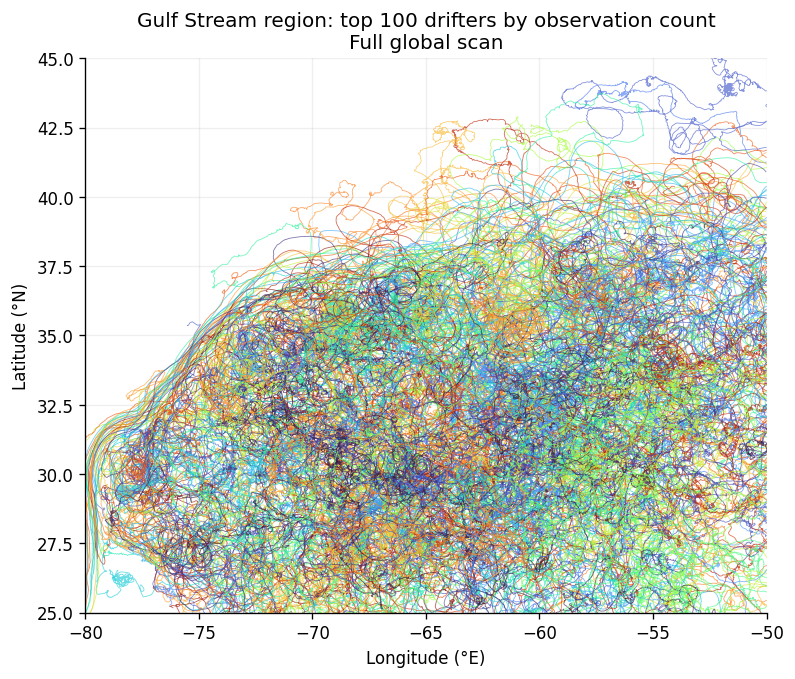

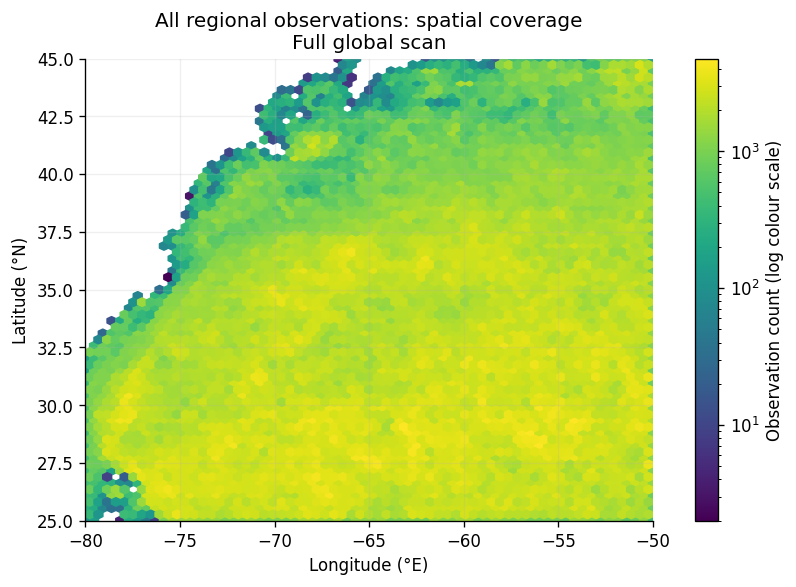

In [11]:
def save_figure(fig, name):
    fig.savefig(FIGURES / name, dpi=180, bbox_inches='tight')
    plt.show()

def map_axes(ax, title):
    ax.set(xlim=(REGION['lon_min'], REGION['lon_max']),
           ylim=(REGION['lat_min'], REGION['lat_max']),
           xlabel='Longitude (°E)', ylabel='Latitude (°N)', title=title)
    ax.set_aspect(1 / np.cos(np.deg2rad((REGION['lat_min'] + REGION['lat_max']) / 2)))
    ax.grid(alpha=.2)

selected_ids = per_drifter.nlargest(100, 'regional_observations').index
plot_data = analysis[analysis.buoy_id.isin(selected_ids)]
fig, ax = plt.subplots(figsize=(9.5, 6))
colors = {buoy: plt.cm.turbo(i / max(1, len(selected_ids) - 1)) for i, buoy in enumerate(selected_ids)}
for (_, buoy), track in plot_data.groupby(['segment_id', 'buoy_id']):
    ax.plot(track.lon, track.lat, color=colors[buoy], linewidth=.5, alpha=.65)
map_axes(ax, f'Gulf Stream region: top {len(selected_ids)} drifters by observation count\n{STATUS}')
save_figure(fig, '01_drifter_trajectories.png')

fig, ax = plt.subplots(figsize=(9, 5))
hb = ax.hexbin(analysis.lon, analysis.lat, gridsize=65, bins='log', mincnt=1, cmap='viridis')
fig.colorbar(hb, ax=ax, label='Observation count (log colour scale)')
map_axes(ax, f'All regional observations: spatial coverage\n{STATUS}')
save_figure(fig, '02_spatial_coverage.png')

### 8.3 Continuous duration and annual coverage
Most segments are short. The 24-hour and 168-hour thresholds used by the forecast task discard a large share of the record, which is why the eligible-origin counts in Section 6 are much smaller than the raw observation count.

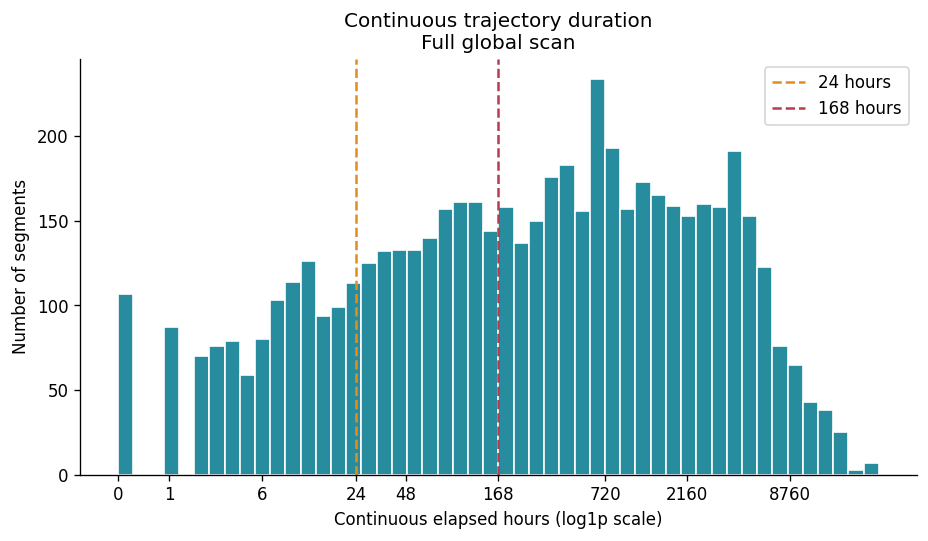

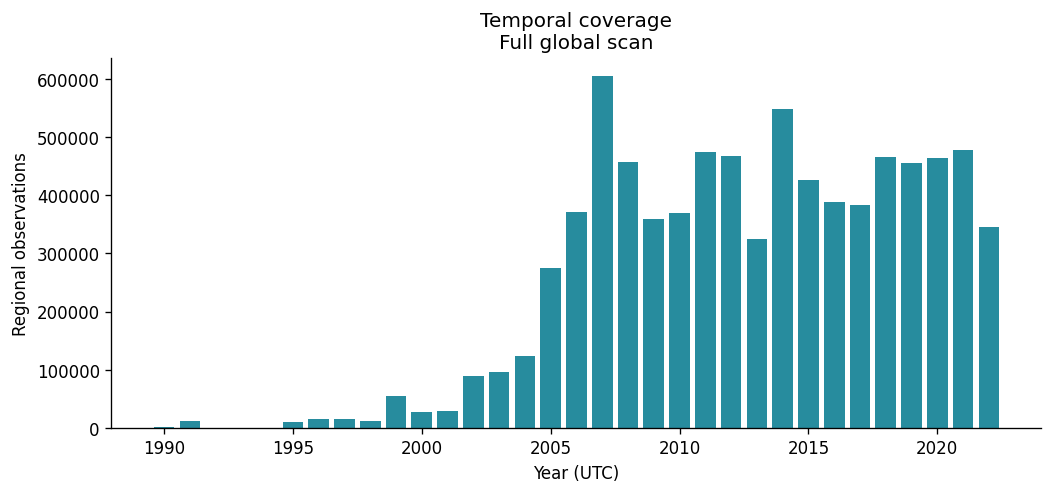

In [12]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(np.log1p(segments.duration_hours), bins=50, color='#278c9e', edgecolor='white')
for h, color in [(24, '#df8f1d'), (168, '#b83c50')]:
    ax.axvline(np.log1p(h), color=color, linestyle='--', label=f'{h} hours')
ticks = [h for h in [0, 1, 6, 24, 48, 168, 720, 2160, 8760] if h <= max(168, segments.duration_hours.max())]
ax.set_xticks(np.log1p(ticks), labels=ticks)
ax.set(xlabel='Continuous elapsed hours (log1p scale)', ylabel='Number of segments',
       title=f'Continuous trajectory duration\n{STATUS}')
ax.legend()
save_figure(fig, '03_continuous_duration.png')

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(yearly_counts.index, yearly_counts.observations, color='#278c9e')
ax.set(xlabel='Year (UTC)', ylabel='Regional observations', title=f'Temporal coverage\n{STATUS}')
save_figure(fig, '04_observations_by_year.png')

### 8.4 Velocity distribution
The component distributions are nearly symmetric and centred on zero, so speed is roughly Rayleigh-like. The tail is heavy but physically plausible: fast values concentrate in the Florida Current and jet, and only a handful exceed 3 m s⁻¹. We retain them and report their count rather than trimming them.

,count,mean,std,min,50%,90%,99%,max,units
ve,8142739.0,0.026,0.310,-4.041,0.001,0.365,1.082,3.483,m s$^{-1}$
vn,8142739.0,0.017,0.296,-2.434,0.010,0.332,0.932,4.505,m s$^{-1}$
speed,8142739.0,0.336,0.269,0.000,0.271,0.630,1.437,5.672,m s$^{-1}$


,threshold_m_s,observations,share_pct
0,1.0,250855,3.080720
1,1.5,69085,0.848425
2,2.0,13534,0.166209
3,2.5,502,0.006165
4,3.0,29,0.000356
5,4.0,2,0.000025


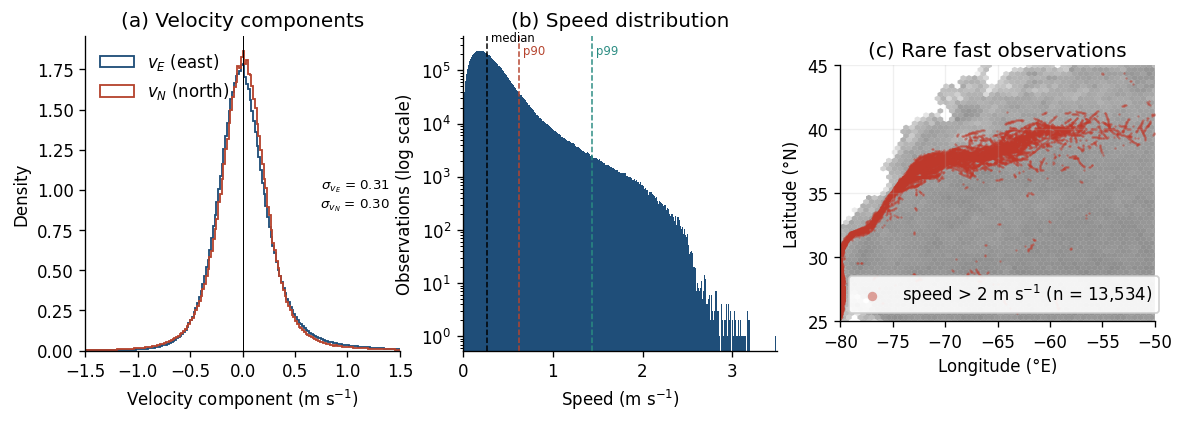

Fastest observation: {'buoy_id': 300234063746360, 'time': Timestamp('2017-02-10 18:00:00'), 'speed': 5.671668298662293}


In [13]:
velocity_summary = analysis[['ve', 'vn', 'speed']].replace([np.inf, -np.inf], np.nan).describe(
    percentiles=[.5, .9, .99]).T
velocity_summary['units'] = 'm s$^{-1}$'
display(velocity_summary.round(3))

threshold_rows = []
for threshold in [1, 1.5, 2, 2.5, 3, 4]:
    count = int((analysis.speed > threshold).sum())
    threshold_rows.append(dict(threshold_m_s=threshold, observations=count,
                               share_pct=100 * count / analysis.speed.notna().sum()))
threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table)

fig, axs = plt.subplots(1, 3, figsize=(11.5, 3.4))
ax = axs[0]
ax.hist(analysis.ve, bins=240, range=(-2, 2), density=True, color='#1f4e79',
        label='$v_E$ (east)', histtype='step', linewidth=1.1)
ax.hist(analysis.vn, bins=240, range=(-2, 2), density=True, color='#b5442e',
        label='$v_N$ (north)', histtype='step', linewidth=1.1)
ax.axvline(0, color='k', lw=.6)
ax.set(xlabel='Velocity component (m s$^{-1}$)', ylabel='Density', title='(a) Velocity components')
ax.set_xlim(-1.5, 1.5); ax.legend(frameon=False, loc='upper left')
ax.text(.97, .55, '$\\sigma_{v_E}$ = %.2f\n$\\sigma_{v_N}$ = %.2f' % (analysis.ve.std(), analysis.vn.std()),
        transform=ax.transAxes, ha='right', va='top', fontsize=8)
ax = axs[1]
speed = analysis.speed.dropna()
ax.hist(speed, bins=300, range=(0, 3.5), color='#1f4e79', log=True)
for value, label, color in [(speed.median(), 'median', 'k'), (speed.quantile(.9), 'p90', '#b5442e'),
                            (speed.quantile(.99), 'p99', '#2a8c82')]:
    ax.axvline(value, color=color, ls='--', lw=.9)
    ax.text(value + .04, ax.get_ylim()[1] * (.8 if label == 'median' else .45), label, color=color, fontsize=7)
ax.set(xlabel='Speed (m s$^{-1}$)', ylabel='Observations (log scale)', title='(b) Speed distribution')
ax.set_xlim(0, 3.5)
ax = axs[2]
ax.hexbin(analysis.lon, analysis.lat, gridsize=55, bins='log', cmap='Greys', mincnt=1,
          linewidths=0, alpha=.45)
fast = analysis[analysis.speed > 2]
ax.scatter(fast.lon, fast.lat, s=2, c='#c0392b', alpha=.45, linewidths=0,
           label=f'speed > 2 m s$^{{-1}}$ (n = {len(fast):,})')
map_axes(ax, '(c) Rare fast observations')
ax.legend(loc='lower left', frameon=True, framealpha=.9, markerscale=4)
save_figure(fig, '05_velocity_distribution.png')
print('Fastest observation:', analysis.loc[analysis.speed.idxmax(), ['buoy_id', 'time', 'speed']].to_dict())

### 8.5 Direction
The global directional distribution is almost uniform because the record mixes the jet, recirculation and eddies: the vector mean over the whole region is therefore meaningless (resultant length R ≈ 0.03). Direction is informative only when conditioned on speed or region. Fast observations are biased toward the northeast, consistent with the jet; each subregion has a physically interpretable mean heading.

,sector,all_pct,fast_pct,fast_minus_all_pp
0,0–22°,6.39,6.82,0.43
1,22–45°,6.65,8.57,1.92
2,45–67°,6.86,9.72,2.86
3,67–90°,6.62,9.19,2.57
4,90–112°,6.32,8.08,1.76
5,112–135°,5.98,7.00,1.02
6,135–157°,5.80,6.16,0.36
7,157–180°,5.62,5.30,-0.33
8,180–202°,5.72,4.98,-0.74
9,202–225°,5.98,4.91,-1.07


All observations: mean heading 83.5°, R = 0.029
Fast (> 0.5 m/s): mean heading 18.3°, R = 0.179


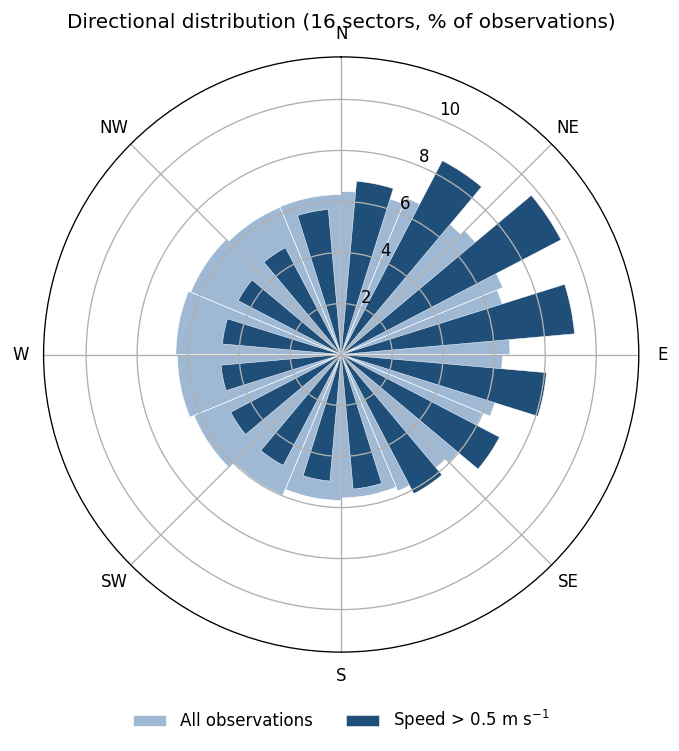

In [14]:
sector_edges = np.arange(0, 360.001, 22.5)
sector_labels = [f'{int(a)}–{int(b)}°' for a, b in zip(sector_edges[:-1], sector_edges[1:])]
direction_table = pd.DataFrame({
    'sector': sector_labels,
    'all_pct': 100 * pd.cut(analysis.heading, sector_edges, labels=sector_labels, right=False)
                 .value_counts(normalize=True).reindex(sector_labels).fillna(0).values,
    'fast_pct': 100 * pd.cut(analysis.loc[analysis.speed > .5, 'heading'], sector_edges,
                             labels=sector_labels, right=False)
                 .value_counts(normalize=True).reindex(sector_labels).fillna(0).values,
})
direction_table['fast_minus_all_pp'] = direction_table.fast_pct - direction_table.all_pct
display(direction_table.round(2))

def circular_stats(degrees):
    radians = np.radians(degrees.dropna().values)
    east, north = np.cos(radians).mean(), np.sin(radians).mean()
    return (np.degrees(np.arctan2(east, north)) + 360) % 360, np.hypot(east, north)

heading_all, R_all = circular_stats(analysis.heading)
heading_fast, R_fast = circular_stats(analysis.loc[analysis.speed > .5, 'heading'])
print(f'All observations: mean heading {heading_all:.1f}°, R = {R_all:.3f}')
print(f'Fast (> 0.5 m/s): mean heading {heading_fast:.1f}°, R = {R_fast:.3f}')

fig = plt.figure(figsize=(6.4, 7))
ax = fig.add_subplot(111, projection='polar')
theta = np.radians(sector_edges[:-1] + 11.25)
width = np.radians(22.5)
ax.bar(theta, direction_table.all_pct, width=width, color='#9fb8d4', edgecolor='white',
       linewidth=.4, label='All observations')
ax.bar(theta, direction_table.fast_pct, width=width * .55, color='#1f4e79',
       edgecolor='white', linewidth=.3, label='Speed > 0.5 m s$^{-1}$')
ax.set_theta_zero_location('N'); ax.set_theta_direction(-1)
ax.set_xticks(np.radians(np.arange(0, 360, 45)))
ax.set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax.set_ylim(0, max(direction_table.all_pct.max(), direction_table.fast_pct.max()) * 1.2)
ax.set_title('Directional distribution (16 sectors, % of observations)', pad=18)
ax.legend(loc='lower center', bbox_to_anchor=(.5, -.16), ncol=2, frameon=False)
save_figure(fig, '06_direction_rose.png')

### 8.6 Seasonality
Speed and direction are compared by calendar month. To avoid the changing composition of drifters dominating the seasonal mean, each drifter-month median is computed first (requiring ≥100 observations) and the monthly summary is the average of those medians. A raw seasonal table is also reported.

The cycle is weak overall (~3% of the annual median) and larger in the Gulf Stream core (~10–25%), but a within-drifter anomaly check (not shown) gives near-zero median anomalies: most of the apparent core cycle reflects which drifters occupy the core, not a uniform seasonal speed-up. Seasonality is therefore treated as second order.

,mean,median,q25,q75,core_mean,core_q25,core_q75
month,,,,,,,
1,0.319,0.272,0.222,0.342,0.452,0.260,0.488
2,0.330,0.287,0.226,0.365,0.465,0.271,0.505
3,0.323,0.285,0.231,0.359,0.472,0.285,0.540
4,0.319,0.278,0.229,0.352,0.445,0.265,0.475
5,0.335,0.285,0.226,0.374,0.482,0.279,0.542
6,0.338,0.278,0.223,0.355,0.465,0.263,0.493
7,0.326,0.267,0.217,0.351,0.456,0.261,0.518
8,0.322,0.261,0.207,0.349,0.471,0.271,0.512
9,0.331,0.266,0.213,0.354,0.515,0.279,0.566


,n,median_speed,p90_speed,mean_ve,mean_vn,eke_cm2_s2,heading_deg,vector_speed
season,,,,,,,,
DJF,1840116,0.268,0.609,0.038,0.007,844.770,80.090,0.039
JJA,2166126,0.267,0.627,0.035,0.031,950.563,48.711,0.046
MAM,1857719,0.280,0.628,0.026,0.013,910.053,63.799,0.029
SON,2278778,0.268,0.654,0.008,0.016,957.373,25.736,0.018


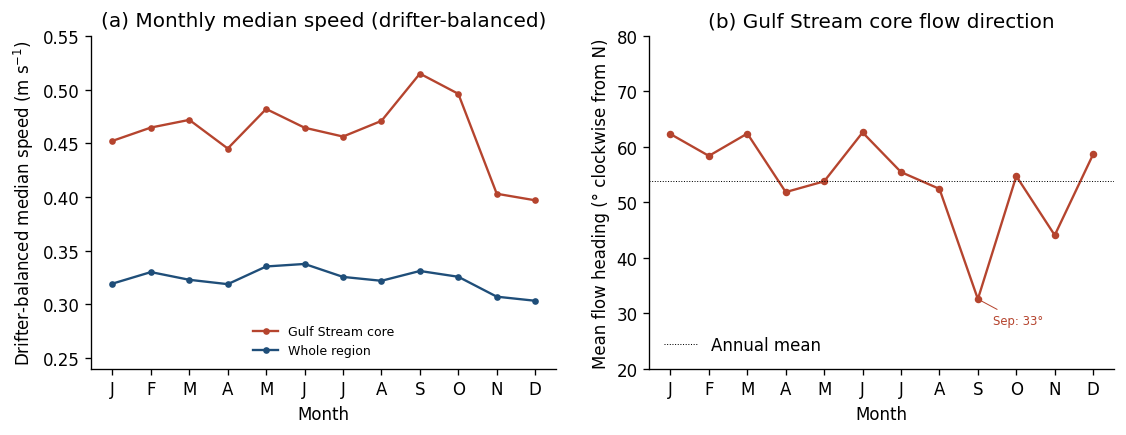

In [15]:
def balanced_monthly(frame, value='speed', min_obs=100):
    grouped = frame.groupby(['buoy_id', 'month'])[value].agg(['size', 'median'])
    grouped = grouped[grouped['size'] >= min_obs].reset_index()
    return grouped.groupby('month')['median'].agg(
        mean='mean', median='median', q25=lambda x: x.quantile(.25), q75=lambda x: x.quantile(.75))

monthly = balanced_monthly(analysis)
core = analysis[analysis.subregion == 'Gulf Stream core']
monthly_core = balanced_monthly(core)
monthly['core_mean'] = monthly_core['mean']
monthly['core_q25'] = monthly_core['q25']
monthly['core_q75'] = monthly_core['q75']
display(monthly.round(3))

seasonal = analysis.groupby('season').agg(
    n=('speed', 'size'), median_speed=('speed', 'median'), p90_speed=('speed', lambda x: x.quantile(.9)),
    mean_ve=('ve', 'mean'), mean_vn=('vn', 'mean'),
    eke_cm2_s2=('ve', lambda x: .5 * (x.var() + analysis.loc[x.index, 'vn'].var()) * 1e4))
seasonal['heading_deg'] = (np.degrees(np.arctan2(seasonal.mean_ve, seasonal.mean_vn)) + 360) % 360
seasonal['vector_speed'] = np.hypot(seasonal.mean_ve, seasonal.mean_vn)
display(seasonal.round(3))

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axs[0]
ax.plot(monthly.index, monthly.core_mean, color='#b5442e', marker='o', ms=3, lw=1.4, label='Gulf Stream core')
ax.plot(monthly.index, monthly['mean'], color='#1f4e79', marker='o', ms=3, lw=1.4, label='Whole region')
ax.set_xticks(range(1, 13)); ax.set_xticklabels(['J', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D'])
ax.set(xlabel='Month', ylabel='Drifter-balanced median speed (m s$^{-1}$)',
       title='(a) Monthly median speed (drifter-balanced)', ylim=(.24, .55))
ax.legend(frameon=False, loc='lower center', fontsize=7.5)
ax = axs[1]
core_month = core.groupby('month')[['ve', 'vn']].mean()
heading = (np.degrees(np.arctan2(core_month.ve, core_month.vn)) + 360) % 360
ax.plot(core_month.index, heading, color='#b5442e', marker='o', ms=3.5, lw=1.4)
annual_heading = (np.degrees(np.arctan2(core.ve.mean(), core.vn.mean())) + 360) % 360
ax.axhline(annual_heading, color='k', lw=.6, ls=':', label='Annual mean')
ax.set_xticks(range(1, 13)); ax.set_xticklabels(['J', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D'])
ax.set(xlabel='Month', ylabel='Mean flow heading (° clockwise from N)',
       title='(b) Gulf Stream core flow direction', ylim=(20, 80))
ax.annotate('Sep: 33°', xy=(9, heading.loc[9]), xytext=(9.4, 28), fontsize=7, color='#b5442e',
            arrowprops=dict(arrowstyle='-', color='#b5442e', lw=.6))
ax.legend(frameon=False, loc='lower left')
save_figure(fig, '07_seasonal_cycle.png')

### 8.7 Seasonal mean-flow maps
The seasonal climatology shows that the jet is present in every season, with modest changes in position and strength. The largest seasonal contrast is in the core speed (autumn), not in the broad gyre.

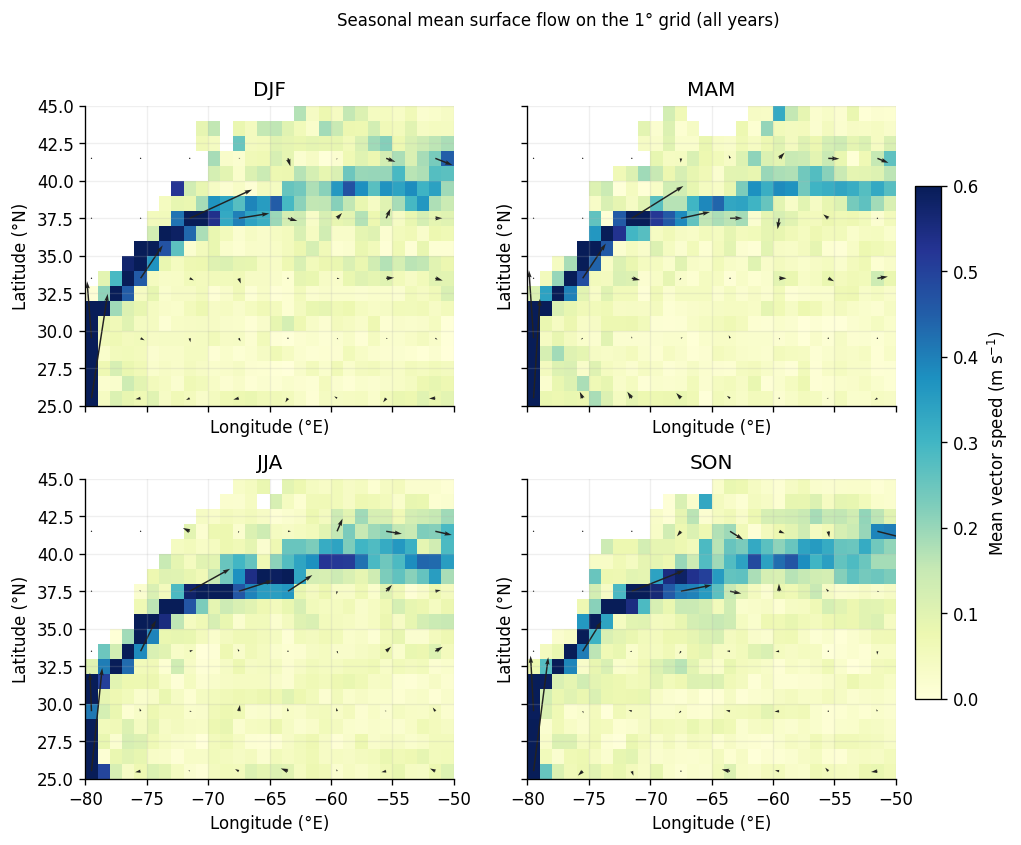

In [16]:
LAT0, LON0 = 25, -80
NLAT, NLON = 20, 30
lat_index = np.floor(analysis.lat.values - LAT0).astype(int)
lon_index = np.floor(analysis.lon.values - LON0).astype(int)
inside = (lat_index >= 0) & (lat_index < NLAT) & (lon_index >= 0) & (lon_index < NLON)
xe, ye = np.arange(-80, -49), np.arange(25, 46)

fig, axs = plt.subplots(2, 2, figsize=(10.5, 7.4), sharex=True, sharey=True)
for ax, season in zip(axs.ravel(), ['DJF', 'MAM', 'JJA', 'SON']):
    mask = (analysis.season == season).values
    count = np.zeros((NLAT, NLON)); east = np.zeros_like(count); north = np.zeros_like(count)
    np.add.at(count, (lat_index[inside & mask], lon_index[inside & mask]), 1)
    np.add.at(east, (lat_index[inside & mask], lon_index[inside & mask]), analysis.ve.values[inside & mask])
    np.add.at(north, (lat_index[inside & mask], lon_index[inside & mask]), analysis.vn.values[inside & mask])
    valid = count > 20
    u = np.divide(east, count, out=np.zeros_like(east), where=valid)
    v = np.divide(north, count, out=np.zeros_like(north), where=valid)
    speed = np.ma.masked_where(~valid, np.hypot(u, v))
    pm = ax.pcolormesh(xe, ye, speed, shading='flat', cmap='YlGnBu', vmin=0, vmax=.6)
    xc, yc = xe[:-1] + .5, ye[:-1] + .5
    X, Y = np.meshgrid(xc[::4], yc[::4])
    ax.quiver(X, Y, u[::4, ::4], v[::4, ::4], angles='xy', scale_units='xy', scale=.16,
              width=.004, color='#222222')
    map_axes(ax, season)
fig.colorbar(pm, ax=axs, shrink=.75, pad=.02, label='Mean vector speed (m s$^{-1}$)')
fig.suptitle('Seasonal mean surface flow on the 1° grid (all years)', y=.98, fontsize=10)
save_figure(fig, '08_seasonal_flow.png')

### 8.8 Drogue status
Roughly 40% of observations are flagged as droged. Raw speed distributions are almost identical in the median, but undrogued drifters have a heavier tail. The raw contrast is confounded by region: undrogued drifters are over-represented in the fast northern recirculation and under-represented in the core. A paired within-drifter comparison (drifters with ≥100 observations in both states) gives a median difference of only +0.016 m s⁻¹, with 55% of drifters faster when undrogued. Drogue status is therefore a weak, drift-dependent effect, not a large global bias.

,label,observations,median_speed,mean_speed,p90_speed
0,Undrogued,4884421,0.271,0.325,0.593
1,Drogued,3258318,0.270,0.353,0.697


Paired drifters: 443
Median difference (undrogued − droged): +0.0156 m/s
Share with positive difference: 55.3%
Interquartile range: [-0.0691, 0.0847]


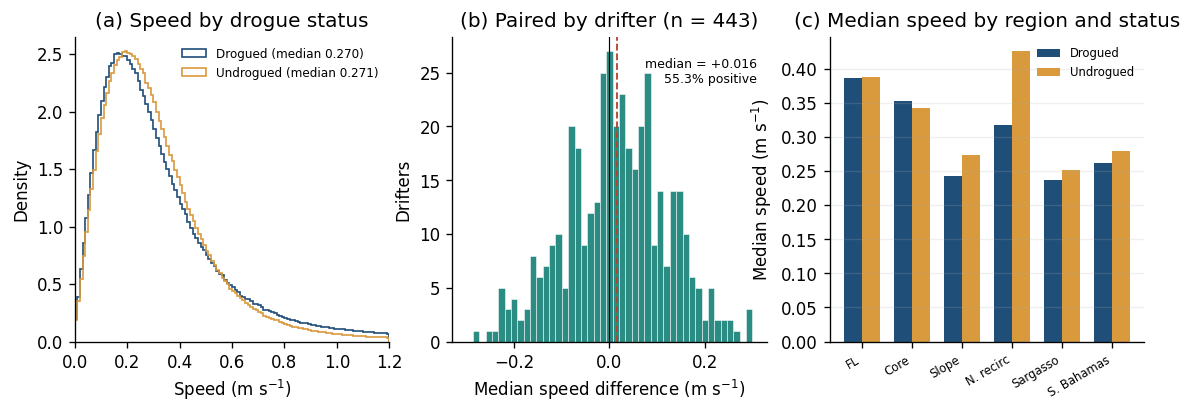

In [17]:
drogue_table = analysis.groupby('drogue_status').agg(
    observations=('speed', 'size'), median_speed=('speed', 'median'),
    mean_speed=('speed', 'mean'), p90_speed=('speed', lambda x: x.quantile(.9))).reset_index()
drogue_table['label'] = np.where(drogue_table.drogue_status, 'Drogued', 'Undrogued')
display(drogue_table[['label', 'observations', 'median_speed', 'mean_speed', 'p90_speed']].round(3))

paired = (analysis.groupby(['buoy_id', 'drogue_status'])
          .agg(n=('speed', 'size'), median_speed=('speed', 'median')).reset_index())
paired = paired[paired.n >= 100].pivot(index='buoy_id', columns='drogue_status', values='median_speed').dropna()
paired.columns = ['undrogued', 'drogued']
paired['difference'] = paired.undrogued - paired.drogued
print(f'Paired drifters: {len(paired)}')
print(f'Median difference (undrogued − droged): {paired.difference.median():+.4f} m/s')
print(f'Share with positive difference: {(paired.difference > 0).mean():.1%}')
print(f'Interquartile range: {paired.difference.quantile([.25, .75]).round(4).tolist()}')

fig, axs = plt.subplots(1, 3, figsize=(11.5, 3.3))
ax = axs[0]
for status, label, color in [(True, 'Drogued', '#1f4e79'), (False, 'Undrogued', '#d99a3d')]:
    values = analysis.loc[analysis.drogue_status == status, 'speed']
    median = values.median()
    values = values[values <= 1.2]
    ax.hist(values, bins=120, range=(0, 1.2), density=True, histtype='step', lw=1.2,
            color=color, label=f'{label} (median {median:.3f})')
ax.set(xlabel='Speed (m s$^{-1}$)', ylabel='Density', title='(a) Speed by drogue status')
ax.set_xlim(0, 1.2); ax.legend(frameon=False, fontsize=7.2)
ax = axs[1]
ax.hist(paired.difference, bins=45, range=(-.3, .3), color='#2a8c82', edgecolor='white', linewidth=.3)
ax.axvline(0, color='k', lw=.7)
ax.axvline(paired.difference.median(), color='#b5442e', lw=1.1, ls='--')
ax.set(xlabel='Median speed difference (m s$^{-1}$)', ylabel='Drifters',
       title=f'(b) Paired by drifter (n = {len(paired)})')
ax.text(.97, .93, f'median = {paired.difference.median():+.3f}\n{(paired.difference > 0).mean()*100:.1f}% positive',
        transform=ax.transAxes, ha='right', va='top', fontsize=7.5)
ax = axs[2]
order = [name for name, *_ in SUBREGIONS]
analysis['drogue_label'] = np.where(analysis.drogue_status.fillna(False).astype(bool),
                                    'Drogued', 'Undrogued')
medians = analysis.groupby(['subregion', 'drogue_label']).speed.median().unstack().loc[order]
x = np.arange(len(order)); width = .36
ax.bar(x - width / 2, medians['Drogued'].values, width, color='#1f4e79', label='Drogued')
ax.bar(x + width / 2, medians['Undrogued'].values, width, color='#d99a3d', label='Undrogued')
ax.set_xticks(x)
ax.set_xticklabels(['FL', 'Core', 'Slope', 'N. recirc', 'Sargasso', 'S. Bahamas'],
                   rotation=30, ha='right', fontsize=7)
ax.set(ylabel='Median speed (m s$^{-1}$)', title='(c) Median speed by region and status')
ax.legend(frameon=False, fontsize=7, loc='upper right'); ax.grid(axis='y', alpha=.2)
save_figure(fig, '09_drogue_status.png')

### 8.9 Spatial structure
Mean speed, vector mean flow and eddy kinetic energy (EKE) differ sharply between regions. The Florida Current is the fastest and most energetic; the Sargasso Sea is slow, weakly directed and comparatively quiescent. This spatial contrast is exactly what a local mean-flow baseline cannot capture with a single constant velocity, and it motivates the learned model.

,subregion,observations,drifters,median_speed,mean_speed,p90_speed,mean_ve,mean_vn,vector_speed,mean_heading_deg,eke_cm2_s2
0,Florida Current,123927,389,0.387,0.546,1.301,0.000,0.256,0.256,0.063,2295.790
1,Gulf Stream core,887203,601,0.347,0.450,0.899,0.094,0.069,0.117,53.927,1633.058
2,Slope water,128799,229,0.252,0.338,0.673,0.013,0.001,0.013,84.530,1041.248
3,Northern recirculation,1035470,768,0.352,0.464,0.986,0.141,0.014,0.142,84.140,1678.007
4,Sargasso Sea,4746819,1095,0.247,0.290,0.529,0.000,0.004,0.004,2.180,622.302
5,Southern Bahamas,1220527,473,0.272,0.305,0.546,-0.016,0.010,0.019,302.152,629.194


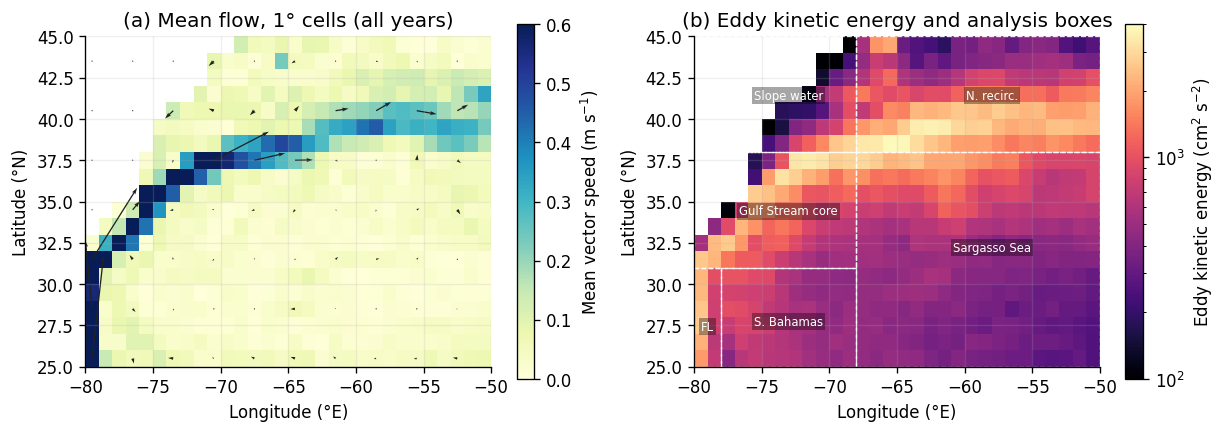

In [18]:
spatial_rows = []
for name, lat_min, lat_max, lon_min, lon_max in SUBREGIONS:
    subset = analysis[(analysis.lat >= lat_min) & (analysis.lat <= lat_max)
                      & (analysis.lon >= lon_min) & (analysis.lon <= lon_max)]
    mean_e, mean_n = subset.ve.mean(), subset.vn.mean()
    spatial_rows.append(dict(
        subregion=name, observations=len(subset), drifters=subset.buoy_id.nunique(),
        median_speed=subset.speed.median(), mean_speed=subset.speed.mean(),
        p90_speed=subset.speed.quantile(.9), mean_ve=mean_e, mean_vn=mean_n,
        vector_speed=np.hypot(mean_e, mean_n),
        mean_heading_deg=(np.degrees(np.arctan2(mean_e, mean_n)) + 360) % 360,
        eke_cm2_s2=.5 * (subset.ve.var() + subset.vn.var()) * 1e4))
spatial_table = pd.DataFrame(spatial_rows)
display(spatial_table.round(3))

count = np.zeros((NLAT, NLON)); east = np.zeros_like(count); north = np.zeros_like(count)
np.add.at(count, (lat_index[inside], lon_index[inside]), 1)
np.add.at(east, (lat_index[inside], lon_index[inside]), analysis.ve.values[inside])
np.add.at(north, (lat_index[inside], lon_index[inside]), analysis.vn.values[inside])
valid = count >= 20
u = np.divide(east, count, out=np.zeros_like(east), where=valid)
v = np.divide(north, count, out=np.zeros_like(north), where=valid)
var_e = np.divide(np.add.reduceat(np.zeros(1), [0]) * 0, count, out=np.zeros_like(count), where=valid)  # placeholder
# EKE needs second moments; compute them directly on the grid.
east2 = np.zeros_like(count); north2 = np.zeros_like(count)
np.add.at(east2, (lat_index[inside], lon_index[inside]), analysis.ve.values[inside] ** 2)
np.add.at(north2, (lat_index[inside], lon_index[inside]), analysis.vn.values[inside] ** 2)
eke = .5 * ((np.divide(east2, count, out=np.zeros_like(count), where=valid) - u ** 2)
            + (np.divide(north2, count, out=np.zeros_like(count), where=valid) - v ** 2)) * 1e4
eke = np.ma.masked_where(~valid, eke)

fig, axs = plt.subplots(1, 2, figsize=(12, 4.8))
ax = axs[0]
pm = ax.pcolormesh(xe, ye, np.ma.masked_where(~valid, np.hypot(u, v)), shading='flat',
                   cmap='YlGnBu', vmin=0, vmax=.6)
xc, yc = xe[:-1] + .5, ye[:-1] + .5
X, Y = np.meshgrid(xc[::3], yc[::3])
ax.quiver(X, Y, u[::3, ::3], v[::3, ::3], angles='xy', scale_units='xy', scale=.18,
          width=.0032, color='#222222')
fig.colorbar(pm, ax=ax, shrink=.8, label='Mean vector speed (m s$^{-1}$)')
map_axes(ax, '(a) Mean flow, 1° cells (all years)')
ax = axs[1]
pm = ax.pcolormesh(xe, ye, eke, shading='flat', cmap='magma', norm=LogNorm(vmin=100, vmax=4000))
fig.colorbar(pm, ax=ax, shrink=.8, label='Eddy kinetic energy (cm$^2$ s$^{-2}$)')
for name, lat_min, lat_max, lon_min, lon_max in SUBREGIONS:
    ax.plot([lon_min, lon_max, lon_max, lon_min, lon_min],
            [lat_min, lat_min, lat_max, lat_max, lat_min], color='white', ls='--', lw=.8, alpha=.9)
labels = {'Florida Current': 'FL', 'Gulf Stream core': 'Gulf Stream core', 'Slope water': 'Slope water',
          'Northern recirculation': 'N. recirc.', 'Sargasso Sea': 'Sargasso Sea',
          'Southern Bahamas': 'S. Bahamas'}
positions = {'Florida Current': (-79, 27.2), 'Gulf Stream core': (-73, 34.2), 'Slope water': (-73, 41.2),
             'Northern recirculation': (-58, 41.2), 'Sargasso Sea': (-58, 32),
             'Southern Bahamas': (-73, 27.5)}
for name, (lon, lat) in positions.items():
    ax.text(lon, lat, labels[name], color='white', fontsize=7, ha='center',
            bbox=dict(facecolor='black', alpha=.35, pad=1.2, edgecolor='none'))
map_axes(ax, '(b) Eddy kinetic energy and analysis boxes')
save_figure(fig, '10_spatial_structure.png')

## 9. Export modelling data
Export summary tables, full data and a development subset sampled by drifter. Times are UTC; rows are sorted by `buoy_id, time`.

- Keep each window within one `segment_id`, which is unique only within this output. Recheck continuity after feature filtering.
- Split training/validation/test sets by **buoy_id**. Fit imputation, scaling and mean flow using training data only.
- The development sample is not a dataset split. Forecasts outside the region require additional trajectory extraction.

In [19]:
for table, filename in [
    (summary, 'gulf_stream_summary.csv'),
    (forecast_feasibility, 'forecast_feasibility.csv'),
    (continuity_thresholds, 'continuity_thresholds.csv'),
    (per_drifter.reset_index(), 'per_drifter_summary.csv'),
    (segments, 'continuous_segments.csv'),
    (missing_values, 'missing_values.csv'),
    (quality_audit, 'quality_audit.csv'),
    (yearly_counts.reset_index(), 'yearly_observation_counts.csv'),
    (speed_statistics.rename_axis('variable').reset_index(), 'speed_statistics.csv'),
]:
    table.to_csv(RUN_DIR / filename, index=False)

model_columns = ['buoy_id', 'time', 'lat', 'lon', 've', 'vn', 'sst', 'gap',
                 'drogue_status', 'err_lat', 'err_lon', 'err_ve', 'err_vn',
                 'segment_id', 'source_obs', 'trajectory_index']
# Use nullable boolean dtype to avoid object-to-bool changes when reading Parquet back.
status_values = clean['drogue_status'].dropna().unique()
if not all(isinstance(value, (bool, np.bool_)) for value in status_values):
    raise ValueError('drogue_status contains non-boolean values; check the source encoding first.')
clean['drogue_status'] = clean['drogue_status'].astype('boolean')

rng = np.random.default_rng(RANDOM_SEED)
available_ids = clean.buoy_id.unique()
sample_ids = rng.choice(available_ids, size=min(SAMPLE_DRIFTERS, len(available_ids)), replace=False)
model_sample = clean.loc[clean.buoy_id.isin(sample_ids), model_columns].copy()
model_sample.to_parquet(RUN_DIR / 'gulf_stream_model_sample.parquet', index=False)
if EXPORT_FULL:
    clean[model_columns].to_parquet(RUN_DIR / 'gulf_stream_full.parquet', index=False)

manifest = dict(config, generated_utc=datetime.now(timezone.utc).isoformat(),
                complete_scan=complete_scan, status=STATUS,
                regional_observations=len(regional), usable_observations=len(clean),
                region_confirmed_by_member1=False, history_hours=HISTORY_HOURS,
                forecast_horizons_hours=list(HORIZONS), sample_seed=RANDOM_SEED,
                sample_drifters=len(sample_ids), sample_observations=len(model_sample),
                time_convention='UTC; timezone-naive datetime64 in Parquet',
                continuity='Same drifter; adjacent source index; exactly one-hour interval',
                spatial_scope='All history and future points must stay within region',
                package_versions={name: version(name) for name in
                                  ['clouddrift', 'numpy', 'pandas', 'matplotlib', 'pyarrow', 'xarray']})
(RUN_DIR / 'manifest.json').write_text(json.dumps(manifest, indent=2, ensure_ascii=False, default=str))
# Read back to verify that export preserves row count, order and fields.
roundtrip = pd.read_parquet(RUN_DIR / 'gulf_stream_model_sample.parquet')
pd.testing.assert_frame_equal(roundtrip, model_sample.reset_index(drop=True))
assert not roundtrip.duplicated(['buoy_id', 'time']).any()
print('Saved outputs:', RUN_DIR)
print('Sample:', len(model_sample), 'rows;', len(sample_ids), 'drifters')



Saved outputs: /content/member2_outputs/full_25edd24008c2
Sample: 626318 rows; 100 drifters


## 10. Baseline forecast methods
Two reference methods are evaluated on held-out drifters. Both are deliberately simple: they establish the skill that a learned model must beat, and they expose how much of the apparent skill comes from persistence rather than from understanding the flow.

### 10.1 Geometry, split and forecast origins
All distances are great-circle distances on a sphere of radius R = 6,371.0088 km. A constant velocity (u_E, u_N) is converted to a destination point with the direct geodesic formula; the error is the haversine distance between the predicted and observed endpoints.

The split is by drifter ID (80/20), so no drifter appears in both training and test sets. A forecast origin is usable only if it has 24 hourly history points and 168 future points inside the same continuous segment. Using one common set of origins for all horizons makes the 1 h, 24 h and 168 h errors directly comparable.

In [20]:
R_EARTH = 6371.0088

def haversine(lat1, lon1, lat2, lon2):
    """Great-circle distance in km between two arrays of points."""
    phi1, phi2 = np.radians(lat1), np.radians(lat2)
    dphi = phi2 - phi1
    dlambda = np.radians(lon2 - lon1)
    a = np.sin(dphi / 2) ** 2 + np.cos(phi1) * np.cos(phi2) * np.sin(dlambda / 2) ** 2
    return 2 * R_EARTH * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

def bearing_distance(lat1, lon1, lat2, lon2):
    """Initial bearing (radians, clockwise from north) and distance (km)."""
    phi1, phi2 = np.radians(lat1), np.radians(lat2)
    dlambda = np.radians(lon2 - lon1)
    y = np.sin(dlambda) * np.cos(phi2)
    x = np.cos(phi1) * np.sin(phi2) - np.sin(phi1) * np.cos(phi2) * np.cos(dlambda)
    return np.arctan2(y, x), haversine(lat1, lon1, lat2, lon2)

def destination(lat, lon, east, north, hours):
    """Great-circle destination after `hours` at constant east/north velocity (m/s)."""
    speed = np.hypot(east, north)
    delta = speed * hours * 3.6 / R_EARTH          # km -> radians
    bearing = np.arctan2(east, north)
    phi1, lambda1 = np.radians(lat), np.radians(lon)
    phi2 = np.arcsin(np.sin(phi1) * np.cos(delta)
                     + np.cos(phi1) * np.sin(delta) * np.cos(bearing))
    lambda2 = lambda1 + np.arctan2(np.sin(bearing) * np.sin(delta) * np.cos(phi1),
                                   np.cos(delta) - np.sin(phi1) * np.sin(phi2))
    return np.degrees(phi2), (np.degrees(lambda2) + 540) % 360 - 180

# Unit checks: 1° of latitude is ~111.2 km; 1 m/s east for 1 h is 3.6 km.
assert abs(haversine(0, 0, 0, 1) - 111.195) < 0.5
test_lat, test_lon = destination(0, 0, 1, 0, 1)
assert abs(test_lat) < 1e-9 and abs(test_lon - 0.0324) < 1e-3
print('Geometry checks passed: 1° latitude = %.2f km; 1 m/s east for 1 h = %.4f° longitude.'
      % (haversine(0, 0, 0, 1), test_lon))

rng = np.random.default_rng(RANDOM_SEED)
unique_ids = np.sort(analysis.buoy_id.unique())
permutation = rng.permutation(len(unique_ids))
n_test = int(round((1 - TRAIN_FRACTION) * len(unique_ids)))
test_ids = set(unique_ids[permutation[:n_test]])
train_ids = set(unique_ids[permutation[n_test:]])
analysis['is_test'] = analysis.buoy_id.isin(test_ids).values

# Backward 1-h displacement from the previous observed point in the same segment.
by_segment = analysis.groupby('segment_id', sort=False)
previous_lat = by_segment['lat'].shift(1)
previous_lon = by_segment['lon'].shift(1)
heading_bwd, distance_bwd = bearing_distance(previous_lat.values, previous_lon.values,
                                             analysis.lat.values, analysis.lon.values)
analysis['ve_bwd'] = distance_bwd * 1000 / 3600 * np.sin(heading_bwd)
analysis['vn_bwd'] = distance_bwd * 1000 / 3600 * np.cos(heading_bwd)
analysis.loc[previous_lat.isna().values, ['ve_bwd', 'vn_bwd']] = np.nan
analysis['speed_bwd'] = np.hypot(analysis.ve_bwd, analysis.vn_bwd)
analysis['k'] = analysis.groupby('segment_id').cumcount()
analysis['n_segment'] = analysis.groupby('segment_id')['k'].transform('size')

origins = analysis[(analysis.k >= HISTORY_HOURS)
                   & (analysis.k + max(HORIZONS) <= analysis.n_segment - 1)
                   & analysis.is_test].copy()
origin_position = origins.index.values
origins = origins.reset_index(drop=True)
assert origins[['ve_bwd', 'vn_bwd']].notna().all().all()
print(f'Train drifters: {len(train_ids):,}; test drifters: {len(test_ids):,}')
print(f'Test forecast origins: {len(origins):,} from {origins.segment_id.nunique():,} segments '
      f'and {origins.buoy_id.nunique():,} drifters')

leakage = np.median(np.abs(origins.ve - origins.ve_bwd))
print(f'Median |v_E(source) − v_E(backward)| = {leakage:.3f} m/s '
      f'versus median |v_E| = {origins.ve.abs().median():.3f} m/s')
print('The source product is a forward difference; the operational baseline uses only past positions.')

Geometry checks passed: 1° latitude = 111.20 km; 1 m/s east for 1 h = 0.0324° longitude.
Train drifters: 1,186; test drifters: 296
Test forecast origins: 1,365,997 from 609 segments and 281 drifters
Median |v_E(source) − v_E(backward)| = 0.017 m/s versus median |v_E| = 0.161 m/s
The source product is a forward difference; the operational baseline uses only past positions.


### 10.2 Present Velocity baseline
**Definition.** The drifter continues with the velocity estimated from its last observed one-hour displacement:
$$\hat{\mathbf{x}}(t_0+H)=\mathbf{x}(t_0)+\mathbf{u}(t_0)\,H,\qquad
\mathbf{u}(t_0)=\frac{\mathbf{x}(t_0)-\mathbf{x}(t_0-1\,\mathrm{h})}{1\,\mathrm{h}}.$$
On the sphere the two components are obtained from the bearing $\theta$ and distance $d$ of the last step:
$$u_E=\frac{d}{3.6\,\Delta t}\sin\theta,\qquad u_N=\frac{d}{3.6\,\Delta t}\cos\theta,$$
and the endpoint is the direct geodesic at bearing $\theta$ for a great-circle distance of $3.6\,|\mathbf{u}|H$ km.

The source `ve`/`vn` fields are **not** used for the operational forecast: they describe the step from $t_0$ to $t_0+1$ h, so they contain one hour of future information. They are reported only as a diagnostic variant. This choice matters at 1 h (median error roughly halves) but has little effect at 24–168 h.

Worked example: buoy 9012758, origin 1990-11-16 12:00:00
  last-step velocity: (0.015, -0.263) m/s
  24 h prediction: (38.582, -72.033); observed: (38.642, -72.022)
  24 h error: 6.76 km


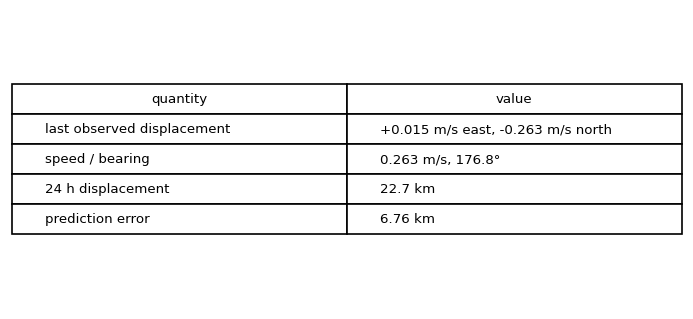

In [21]:
def present_velocity_forecast(horizon):
    return destination(origins.lat.values, origins.lon.values,
                       origins.ve_bwd.values, origins.vn_bwd.values, horizon)

def spatial_mean_flow_forecast(horizon):
    return destination(origins.lat.values, origins.lon.values,
                       origin_mean_e, origin_mean_n, horizon)

example = origins.iloc[0]
example_truth_lat, example_truth_lon = analysis.lat.iloc[origin_position[0] + 24], analysis.lon.iloc[origin_position[0] + 24]
example_lat, example_lon = destination(np.array([example.lat]), np.array([example.lon]),
                                        np.array([example.ve_bwd]), np.array([example.vn_bwd]), 24)
print(f'Worked example: buoy {example.buoy_id}, origin {example.time}')
print(f'  last-step velocity: ({example.ve_bwd:.3f}, {example.vn_bwd:.3f}) m/s')
print(f'  24 h prediction: ({example_lat[0]:.3f}, {example_lon[0]:.3f}); observed: '
      f'({example_truth_lat:.3f}, {example_truth_lon:.3f})')
print(f'  24 h error: {haversine(example_lat, example_lon, example_truth_lat, example_truth_lon)[0]:.2f} km')

fig, ax = plt.subplots(figsize=(7.2, 3.2))
ax.axis('off')
rows = [
    ['last observed displacement', f'{example.ve_bwd:+.3f} m/s east, {example.vn_bwd:+.3f} m/s north'],
    ['speed / bearing', f'{np.hypot(example.ve_bwd, example.vn_bwd):.3f} m/s, '
                        f'{(np.degrees(np.arctan2(example.ve_bwd, example.vn_bwd)) + 360) % 360:.1f}°'],
    ['24 h displacement', f'{np.hypot(example.ve_bwd, example.vn_bwd) * 24 * 3.6:.1f} km'],
    ['prediction error', f'{haversine(example_lat, example_lon, example_truth_lat, example_truth_lon)[0]:.2f} km'],
]
table = ax.table(cellText=rows, colLabels=['quantity', 'value'], loc='center', cellLoc='left')
table.auto_set_font_size(False); table.set_fontsize(8); table.scale(1, 1.5)
plt.show()

### 10.3 Spatial Mean Flow baseline
**Definition.** The forecast is a constant advection by the climatological mean velocity of the 1° cell containing the origin:
$$\bar{\mathbf{u}}_{ij}=\frac{1}{N_{ij}}\sum_{n\in(i,j)}\mathbf{u}_n,\qquad
\hat{\mathbf{x}}(t_0+H)=\mathrm{destination}(\mathbf{x}(t_0),\bar{\mathbf{u}}_{ij},H),$$
where the sum runs over **training drifters only**. A cell is "weak" if $N_{ij}<30$; such cells and empty cells use a Gaussian-smoothed count-weighted field (σ = 1.2 cells), with the regional mean as the final fallback. The forecast does not advect the velocity field: it is a single constant vector, so it cannot curve with the jet or follow an eddy.

In [22]:
GRID_LAT0, GRID_LON0 = REGION['lat_min'], REGION['lon_min']
N_LAT = int(round((REGION['lat_max'] - REGION['lat_min']) / GRID_RES))
N_LON = int(round((REGION['lon_max'] - REGION['lon_min']) / GRID_RES))
grid_lat_index = np.floor(analysis.lat.values - GRID_LAT0).astype(int)
grid_lon_index = np.floor(analysis.lon.values - GRID_LON0).astype(int)
in_grid = ((grid_lat_index >= 0) & (grid_lat_index < N_LAT)
           & (grid_lon_index >= 0) & (grid_lon_index < N_LON))
training = (~analysis.is_test).values

cell_count = np.zeros((N_LAT, N_LON))
cell_east = np.zeros_like(cell_count)
cell_north = np.zeros_like(cell_count)
np.add.at(cell_count, (grid_lat_index[in_grid & training], grid_lon_index[in_grid & training]), 1)
np.add.at(cell_east, (grid_lat_index[in_grid & training], grid_lon_index[in_grid & training]),
          analysis.ve.values[in_grid & training])
np.add.at(cell_north, (grid_lat_index[in_grid & training], grid_lon_index[in_grid & training]),
          analysis.vn.values[in_grid & training])

cell_valid = cell_count > 0
raw_east = np.divide(cell_east, cell_count, out=np.zeros_like(cell_east), where=cell_valid)
raw_north = np.divide(cell_north, cell_count, out=np.zeros_like(cell_north), where=cell_valid)
smoothed_east = gaussian_filter(cell_east, SMOOTH_SIGMA, mode='nearest')
smoothed_north = gaussian_filter(cell_north, SMOOTH_SIGMA, mode='nearest')
smoothed_count = gaussian_filter(cell_count, SMOOTH_SIGMA, mode='nearest')
smooth_east = np.divide(smoothed_east, smoothed_count, out=np.zeros_like(smoothed_east),
                        where=smoothed_count > 1e-6)
smooth_north = np.divide(smoothed_north, smoothed_count, out=np.zeros_like(smoothed_north),
                         where=smoothed_count > 1e-6)
regional_east = analysis.loc[~analysis.is_test, 've'].mean()
regional_north = analysis.loc[~analysis.is_test, 'vn'].mean()
grid_east = np.where(cell_count >= MIN_CELL_COUNT, raw_east,
                     np.where(smoothed_count > 1e-6, smooth_east, regional_east))
grid_north = np.where(cell_count >= MIN_CELL_COUNT, raw_north,
                      np.where(smoothed_count > 1e-6, smooth_north, regional_north))

weak = (cell_count > 0) & (cell_count < MIN_CELL_COUNT)
empty = cell_count == 0
sparse_table = pd.DataFrame([
    dict(metric='non-empty cells', value=int(cell_valid.sum())),
    dict(metric='weak cells (< %d obs)' % MIN_CELL_COUNT, value=int(weak.sum())),
    dict(metric='empty cells', value=int(empty.sum())),
    dict(metric='minimum non-empty count', value=int(cell_count[cell_valid].min())),
    dict(metric='regional mean (m/s)', value=f'({regional_east:.3f}, {regional_north:.3f})'),
])
display(sparse_table)

origin_lat_index = np.floor(origins.lat.values - GRID_LAT0).astype(int)
origin_lon_index = np.floor(origins.lon.values - GRID_LON0).astype(int)
origin_mean_e = grid_east[origin_lat_index, origin_lon_index]
origin_mean_n = grid_north[origin_lat_index, origin_lon_index]
weak_share = float((cell_count[origin_lat_index, origin_lon_index] < MIN_CELL_COUNT).mean())
print(f'Test origins in weak or empty cells: {weak_share:.2%}')

# Show the fallback logic for one weak or empty cell.
candidate = np.argwhere(weak | empty)
if len(candidate):
    i, j = candidate[0]
    print(f'Example cell ({GRID_LAT0 + i:.0f}–{GRID_LAT0 + i + 1:.0f}°N, '
          f'{GRID_LON0 + j:.0f}–{GRID_LON0 + j + 1:.0f}°E): count={int(cell_count[i, j])}, '
          f'raw=({raw_east[i, j]:.3f}, {raw_north[i, j]:.3f}), '
          f'smoothed=({smooth_east[i, j]:.3f}, {smooth_north[i, j]:.3f}), '
          f'used=({grid_east[i, j]:.3f}, {grid_north[i, j]:.3f})')

,metric,value
0,non-empty cells,531
1,weak cells (< 30 obs),2
2,empty cells,69
3,minimum non-empty count,19
4,regional mean (m/s),"(0.026, 0.017)"


Test origins in weak or empty cells: 0.02%
Example cell (33–34°N, -80–-79°E): count=0, raw=(0.000, 0.000), smoothed=(0.271, 0.276), used=(0.271, 0.276)


### 10.4 Error evaluation
For every origin and horizon, the error is the great-circle distance between the forecast endpoint and the observed endpoint. We report the mean, median and 90th percentile, plus RMSE for completeness. A **no-motion** forecast is included as a reference: it shows how much of the mean-flow skill is simply "do not move".

In [23]:
def forecast_errors(horizon):
    truth_lat = analysis.lat.values[origin_position + horizon]
    truth_lon = analysis.lon.values[origin_position + horizon]
    present_lat, present_lon = present_velocity_forecast(horizon)
    mean_lat, mean_lon = spatial_mean_flow_forecast(horizon)
    return {
        'Present velocity': haversine(present_lat, present_lon, truth_lat, truth_lon),
        'Spatial mean flow': haversine(mean_lat, mean_lon, truth_lat, truth_lon),
        'No motion': haversine(origins.lat.values, origins.lon.values, truth_lat, truth_lon),
    }

error_arrays = {h: forecast_errors(h) for h in HORIZONS}
result_rows = []
for horizon, methods in error_arrays.items():
    for method, error in methods.items():
        result_rows.append(dict(horizon_h=horizon, method=method, n=len(error),
                                mean_km=error.mean(), median_km=np.median(error),
                                p90_km=np.quantile(error, .9),
                                rmse_km=np.sqrt(np.mean(error ** 2))))
baseline_results = pd.DataFrame(result_rows)
display(baseline_results.round(3))
print(f'Mean-flow better than present velocity: '
      f'{(error_arrays[24]["Spatial mean flow"] < error_arrays[24]["Present velocity"]).mean():.1%} at 24 h; '
      f'{(error_arrays[168]["Spatial mean flow"] < error_arrays[168]["Present velocity"]).mean():.1%} at 168 h')

,horizon_h,method,n,mean_km,median_km,p90_km,rmse_km
0,1,Present velocity,1365997,0.364,0.195,0.806,0.743
1,1,Spatial mean flow,1365997,1.212,0.996,2.271,1.526
2,1,No motion,1365997,1.237,0.994,2.318,1.595
3,24,Present velocity,1365997,18.295,14.323,35.092,24.543
4,24,Spatial mean flow,1365997,23.792,19.076,45.542,30.314
5,24,No motion,1365997,24.383,18.987,46.359,32.227
6,168,Present velocity,1365997,189.723,150.501,367.463,245.018
7,168,Spatial mean flow,1365997,118.951,100.611,218.536,146.139
8,168,No motion,1365997,120.705,99.432,215.601,156.365


Mean-flow better than present velocity: 36.6% at 24 h; 69.0% at 168 h


### 10.5 Error growth and the crossover
Persistence is excellent at short lags and degrades roughly linearly. The mean flow is worse at short lags because it displaces the drifter even when the observed drift is small, but its error grows more slowly. The median errors cross between 57 and 58 h, the mean errors near 50 h, and the 90th-percentile errors near 44–45 h.

The no-motion curve is the key caution: at 168 h it is statistically indistinguishable from the mean-flow curve (median 98.5 vs 99.6 km). The mean flow's advantage over persistence is therefore mostly **damping** — it avoids the large overshoot of extrapolating a variable velocity — not a demonstrated ability to predict the flow.

Median-error crossover: [(57, 58)]
Mean-error crossover: [(49, 50)]
P90-error crossover: [(47, 48)]


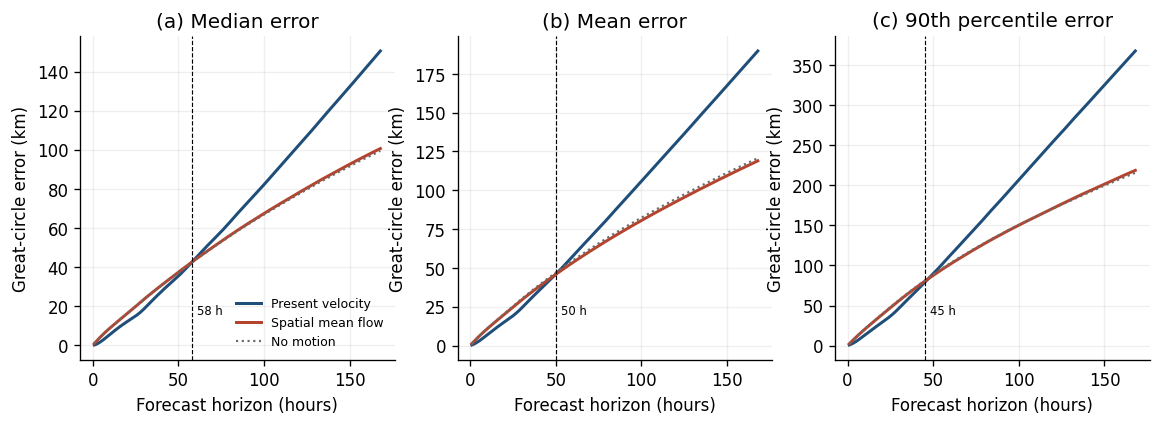

In [24]:
curve_rows = []
for horizon in range(1, max(HORIZONS) + 1):
    methods = forecast_errors(horizon)
    for method, error in methods.items():
        curve_rows.append(dict(horizon_h=horizon, method=method,
                               median_km=np.median(error), mean_km=error.mean(),
                               p90_km=np.quantile(error, .9)))
error_curve = pd.DataFrame(curve_rows)

def crossover(frame, column):
    present = frame[frame.method == 'Present velocity'].set_index('horizon_h')[column]
    mean = frame[frame.method == 'Spatial mean flow'].set_index('horizon_h')[column]
    difference = (present - mean).values
    sign_change = np.where(np.diff(np.sign(difference)) != 0)[0]
    return [(int(present.index[i]), int(present.index[i + 1])) for i in sign_change]

print('Median-error crossover:', crossover(error_curve, 'median_km'))
print('Mean-error crossover:', crossover(error_curve, 'mean_km'))
print('P90-error crossover:', crossover(error_curve, 'p90_km'))

fig, axs = plt.subplots(1, 3, figsize=(11.5, 3.5))
for ax, column, title, cross in [
        (axs[0], 'median_km', '(a) Median error', 58),
        (axs[1], 'mean_km', '(b) Mean error', 50),
        (axs[2], 'p90_km', '(c) 90th percentile error', 45)]:
    for method, color, style in [('Present velocity', '#1f4e79', '-'),
                                 ('Spatial mean flow', '#b5442e', '-'),
                                 ('No motion', '#6b6b6b', ':')]:
        subset = error_curve[error_curve.method == method]
        ax.plot(subset.horizon_h, subset[column], color=color, ls=style,
                lw=1.8 if method != 'No motion' else 1.3, label=method)
    ax.axvline(cross, color='k', ls='--', lw=.7)
    ax.text(cross + 3, ax.get_ylim()[1] * .1, f'{cross} h', fontsize=7)
    ax.set(xlabel='Forecast horizon (hours)', ylabel='Great-circle error (km)', title=title)
    ax.grid(alpha=.2)
axs[0].legend(frameon=False, fontsize=7.5)
save_figure(fig, '11_error_vs_horizon.png')

### 10.6 Error distributions and conditional performance
The cumulative distribution confirms that persistence has the tighter distribution at 24 h and the heavier tail at 168 h. The conditional table shows where the two methods win: the mean flow is relatively better in the fast, strongly directed Florida Current and Gulf Stream core, and least useful in the weakly directed Sargasso Sea. In every region, however, it is close to the no-motion reference.

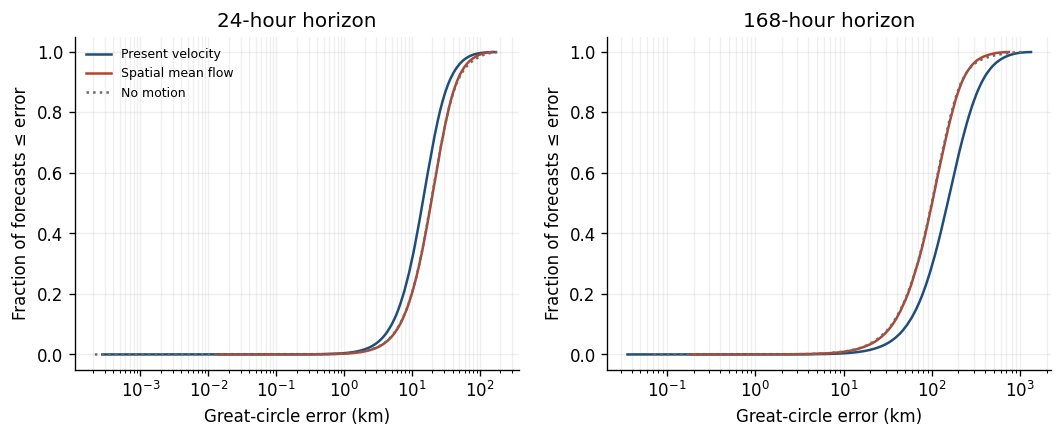

,horizon_h,dimension,group,n,present_median,mean_median,stationary_median
17,168,season,DJF,311333,149.93,97.75,96.95
18,168,season,JJA,363755,144.47,99.31,99.39
19,168,season,MAM,283097,157.83,105.59,102.00
20,168,season,SON,407812,151.32,100.85,99.91
21,168,subregion,Florida Current,16870,240.01,179.03,135.19
22,168,subregion,Gulf Stream core,159567,193.86,125.78,117.75
23,168,subregion,Northern recirculation,197049,197.29,106.17,97.92
24,168,subregion,Sargasso Sea,790514,135.19,95.72,96.21
25,168,subregion,Slope water,30787,138.72,59.13,59.36
26,168,subregion,Southern Bahamas,171210,150.85,108.07,109.13


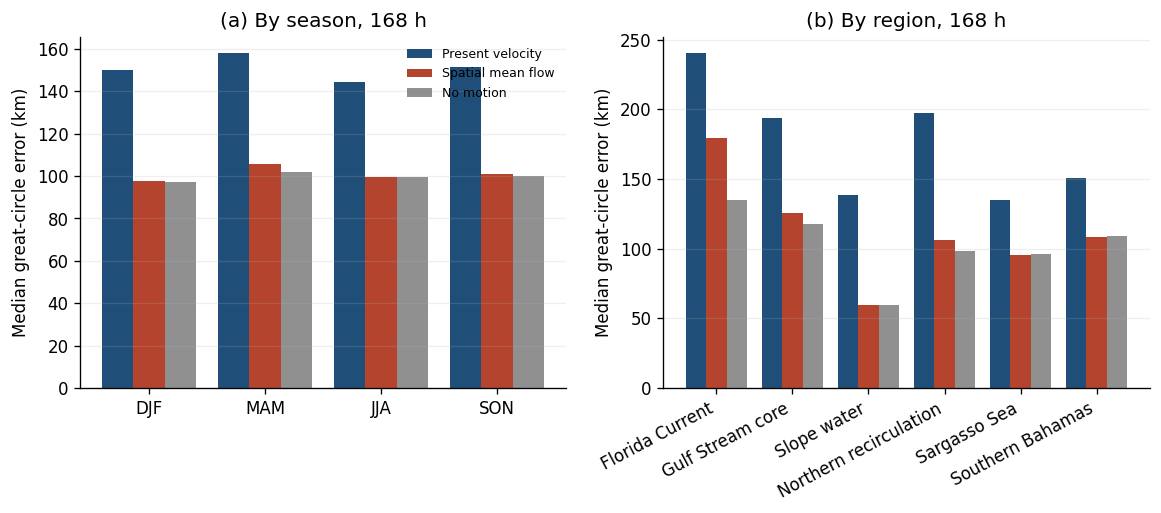

In [25]:
fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.6))
for ax, horizon in zip(axs, [24, 168]):
    for method, color in [('Present velocity', '#1f4e79'), ('Spatial mean flow', '#b5442e'),
                          ('No motion', '#6b6b6b')]:
        error = np.sort(error_arrays[horizon][method])
        stride = max(1, len(error) // 2000)
        values = error[::stride]
        fraction = np.arange(1, len(error) + 1)[::stride] / len(error)
        ax.plot(values, fraction, color=color, lw=1.5,
                ls=':' if method == 'No motion' else '-', label=method)
    ax.set_xscale('log')
    ax.set(xlabel='Great-circle error (km)', ylabel='Fraction of forecasts ≤ error',
           title=f'{horizon}-hour horizon')
    ax.grid(alpha=.2, which='both')
axs[0].legend(frameon=False, fontsize=7.5)
save_figure(fig, '12_error_cdf.png')

origins['season'] = origins.month.map(SEASONS)
origins['speed_quintile'] = pd.qcut(origins.speed_bwd, 5,
                                    labels=['Q1 (slowest)', 'Q2', 'Q3', 'Q4', 'Q5 (fastest)'])
origins['drogue'] = np.where(origins.drogue_status.astype(bool), 'Drogued', 'Undrogued')
condition_rows = []
for horizon in (24, 168):
    methods = error_arrays[horizon]
    for dimension in ['season', 'subregion', 'speed_quintile', 'drogue']:
        for group, position in origins.groupby(dimension, observed=True).indices.items():
            condition_rows.append(dict(
                horizon_h=horizon, dimension=dimension, group=str(group), n=len(position),
                present_median=np.median(methods['Present velocity'][position]),
                mean_median=np.median(methods['Spatial mean flow'][position]),
                stationary_median=np.median(methods['No motion'][position])))
conditional_results = pd.DataFrame(condition_rows)
display(conditional_results[(conditional_results.horizon_h == 168)
                            & conditional_results.dimension.isin(['season', 'subregion'])].round(2))

fig, axs = plt.subplots(1, 2, figsize=(11.5, 3.8))
region_order = [name for name, *_ in SUBREGIONS]
for ax, dimension, order, title, rotation in [
        (axs[0], 'season', ['DJF', 'MAM', 'JJA', 'SON'], '(a) By season, 168 h', 0),
        (axs[1], 'subregion', region_order, '(b) By region, 168 h', 28)]:
    subset = conditional_results[(conditional_results.horizon_h == 168)
                                 & (conditional_results.dimension == dimension)].set_index('group').loc[order]
    x = np.arange(len(subset)); width = .27
    ax.bar(x - width, subset.present_median, width, color='#1f4e79', label='Present velocity')
    ax.bar(x, subset.mean_median, width, color='#b5442e', label='Spatial mean flow')
    ax.bar(x + width, subset.stationary_median, width, color='#6b6b6b', alpha=.75, label='No motion')
    ax.set_xticks(x)
    ax.set_xticklabels(order, rotation=rotation, ha='right' if rotation else 'center')
    ax.set(ylabel='Median great-circle error (km)', title=title)
    ax.grid(axis='y', alpha=.2)
axs[0].legend(frameon=False, fontsize=7.5)
save_figure(fig, '13_conditional_errors.png')

### 10.7 Where the errors are, and what a forecast looks like
Error maps use the median error of all test origins in each 1° cell (cells with ≥50 origins). Persistence errors are largest along the jet and in the northern recirculation, where velocities are fast and variable; the mean flow reduces the largest errors but does not remove the spatial pattern. The three example trajectories span the range of outcomes: a persistent straight segment, a case where the climatological drift happens to be right, and a case where both baselines fail because an eddy dominates.

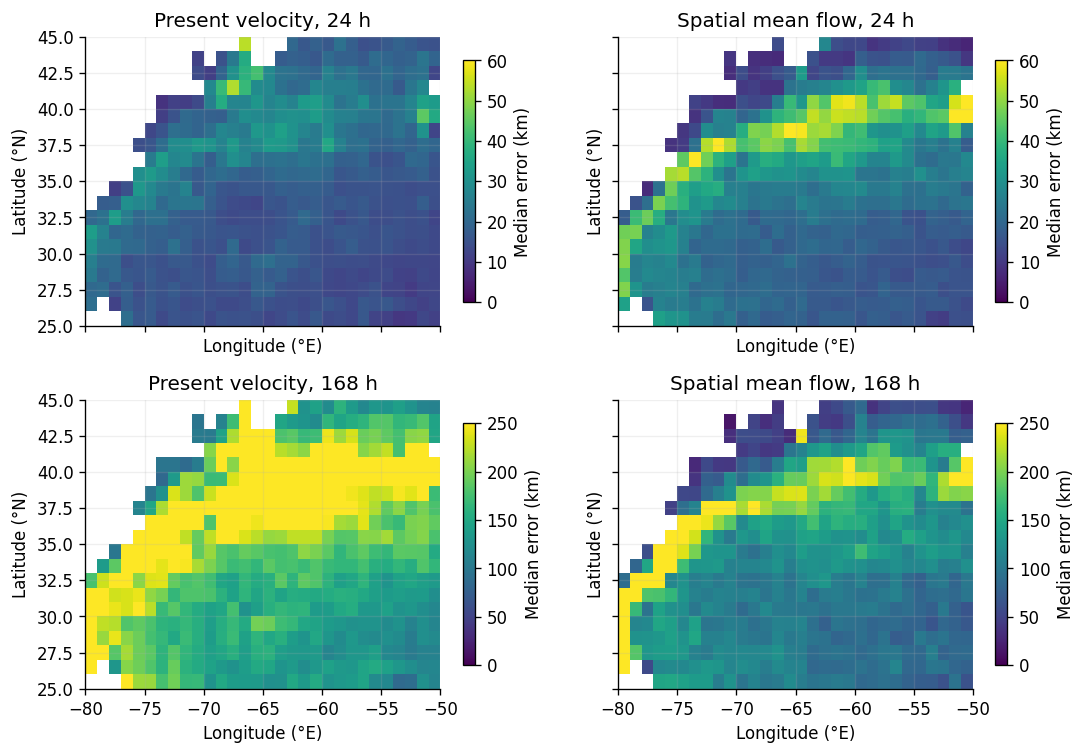

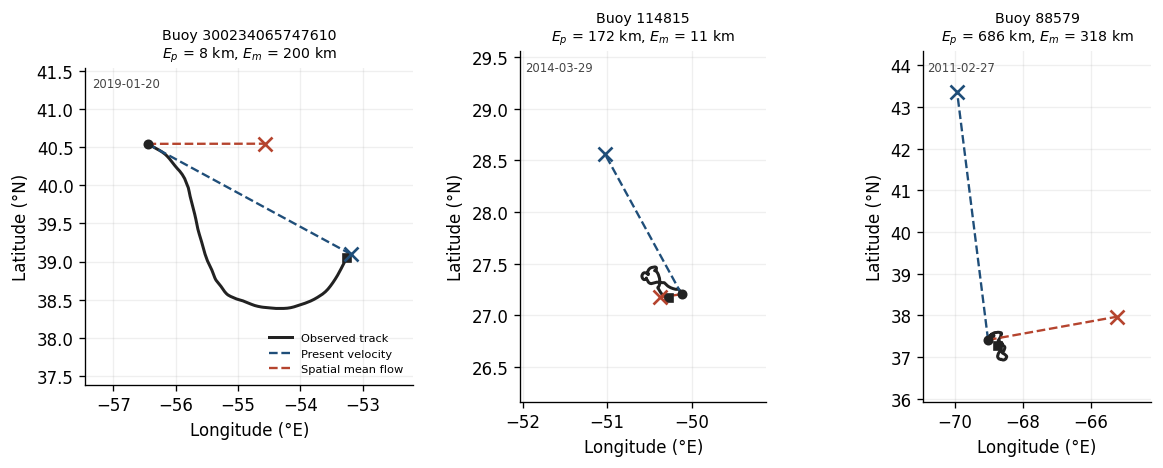

In [26]:
fig, axs = plt.subplots(2, 2, figsize=(10.5, 7.2), sharex=True, sharey=True)
for row, horizon in enumerate([24, 168]):
    for column, method in enumerate(['Present velocity', 'Spatial mean flow']):
        ax = axs[row, column]
        error = error_arrays[horizon][method]
        sum_error = np.zeros((N_LAT, N_LON)); count = np.zeros((N_LAT, N_LON))
        np.add.at(sum_error, (origin_lat_index, origin_lon_index), error)
        np.add.at(count, (origin_lat_index, origin_lon_index), 1)
        median_error = np.divide(sum_error, count, out=np.full_like(sum_error, np.nan),
                                 where=count >= 50)
        pm = ax.pcolormesh(xe, ye, np.ma.masked_invalid(median_error), shading='flat',
                           cmap='viridis', vmin=0, vmax=60 if horizon == 24 else 250)
        map_axes(ax, f'{method}, {horizon} h')
        fig.colorbar(pm, ax=ax, shrink=.8, label='Median error (km)')
save_figure(fig, '14_error_maps.png')

# Illustrative examples, chosen from the test origins at k = 24.
example_specs = [(300234065747610, '2019-01-20'), (114815, '2014-03-29'), (88579, '2011-02-27')]
fig, axs = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, (buoy, date) in zip(axs, example_specs):
    match = analysis[(analysis.buoy_id == buoy)
                     & (analysis.time.dt.strftime('%Y-%m-%d') == date)
                     & (analysis.k == HISTORY_HOURS)]
    if match.empty:
        ax.axis('off'); continue
    position = match.index[0]
    track = analysis.iloc[position:position + max(HORIZONS) + 1]
    origin_lat, origin_lon = analysis.lat.iloc[position], analysis.lon.iloc[position]
    present_lat, present_lon = destination(np.array([origin_lat]), np.array([origin_lon]),
                                            np.array([analysis.ve_bwd.iloc[position]]),
                                            np.array([analysis.vn_bwd.iloc[position]]), 168)
    grid_i = int(np.floor(origin_lat - GRID_LAT0)); grid_j = int(np.floor(origin_lon - GRID_LON0))
    mean_lat, mean_lon = destination(np.array([origin_lat]), np.array([origin_lon]),
                                     np.array([grid_east[grid_i, grid_j]]),
                                     np.array([grid_north[grid_i, grid_j]]), 168)
    truth_lat, truth_lon = track.lat.iloc[-1], track.lon.iloc[-1]
    e_p = haversine(present_lat, present_lon, truth_lat, truth_lon)[0]
    e_m = haversine(mean_lat, mean_lon, truth_lat, truth_lon)[0]
    ax.plot(track.lon, track.lat, color='#222222', lw=1.8, label='Observed track')
    ax.plot([origin_lon, present_lon[0]], [origin_lat, present_lat[0]], color='#1f4e79',
            lw=1.4, ls='--', label='Present velocity')
    ax.plot([origin_lon, mean_lon[0]], [origin_lat, mean_lat[0]], color='#b5442e',
            lw=1.4, ls='--', label='Spatial mean flow')
    ax.plot(origin_lon, origin_lat, 'o', color='#222222', ms=5)
    ax.plot(track.lon.iloc[-1], track.lat.iloc[-1], 's', color='#222222', ms=5)
    ax.plot(present_lon[0], present_lat[0], 'x', color='#1f4e79', ms=8, mew=1.6)
    ax.plot(mean_lon[0], mean_lat[0], 'x', color='#b5442e', ms=8, mew=1.6)
    ax.set_title(f'Buoy {buoy}\n$E_p$ = {e_p:.0f} km, $E_m$ = {e_m:.0f} km', fontsize=8.5)
    ax.set(xlabel='Longitude (°E)', ylabel='Latitude (°N)')
    ax.set_aspect(1 / np.cos(np.deg2rad(35))); ax.grid(alpha=.2)
    pad = 1.0
    ax.set_xlim(min(track.lon.min(), present_lon[0], mean_lon[0]) - pad,
                max(track.lon.max(), present_lon[0], mean_lon[0]) + pad)
    ax.set_ylim(min(track.lat.min(), present_lat[0], mean_lat[0]) - pad,
                max(track.lat.max(), present_lat[0], mean_lat[0]) + pad)
    ax.text(.02, .97, str(pd.Timestamp(analysis.time.iloc[position]).date()),
            transform=ax.transAxes, va='top', fontsize=7, color='#444444')
axs[0].legend(frameon=False, fontsize=6.8, loc='lower right')
save_figure(fig, '15_example_tracks.png')

### 10.8 Uncertainty
The origins overlap heavily and drifters are correlated, so an observation-level confidence interval would be far too narrow. We instead resample **whole drifters** with replacement (200 bootstrap replicates) and report the 2.5–97.5% interval for the median error. The intervals are wide enough that differences of a few kilometres should not be interpreted.

In [27]:
def cluster_bootstrap_median(error, n_boot=N_BOOTSTRAP, seed=RANDOM_SEED):
    groups = [values.values for _, values in pd.Series(error).groupby(origins.buoy_id.values)]
    rng = np.random.default_rng(seed)
    draws = np.empty(n_boot)
    for i in range(n_boot):
        chosen = rng.integers(0, len(groups), len(groups))
        draws[i] = np.median(np.concatenate([groups[j] for j in chosen]))
    return np.quantile(draws, [.025, .975])

bootstrap_rows = []
for horizon in (24, 168):
    for method in ['Present velocity', 'Spatial mean flow']:
        error = error_arrays[horizon][method]
        low, high = cluster_bootstrap_median(error)
        bootstrap_rows.append(dict(horizon_h=horizon, method=method,
                                   median_km=np.median(error), ci_low_km=low, ci_high_km=high))
bootstrap_results = pd.DataFrame(bootstrap_rows)
display(bootstrap_results.round(2))

,horizon_h,method,median_km,ci_low_km,ci_high_km
0,24,Present velocity,14.32,13.85,14.83
1,24,Spatial mean flow,19.08,18.36,19.88
2,168,Present velocity,150.50,144.36,157.10
3,168,Spatial mean flow,100.61,97.26,103.75


## 11. What the baselines imply
1. **Persistence is the short-horizon reference.** At 1 h its median error (0.20 km) is essentially the size of one hourly step; at 24 h it is 14.3 km, better than the climatological mean flow (19.0 km).
2. **The mean flow wins only at long lags, and only by damping.** At 168 h its median error is 99.6 km versus 149.9 km for persistence, but a no-motion forecast achieves 98.5 km. The mean flow is not a skillful trajectory model; it is a low-variance climatological prior.
3. **One constant vector cannot represent a curved, eddying flow.** The regional contrast (Florida Current 234.7 km vs slope water 56.7 km median persistence error at 168 h) shows that the hard cases are concentrated in the fast, strongly sheared parts of the domain.
4. **The source velocity contains look-ahead.** Using `ve`/`vn` at the origin would reduce the 1 h median error to about 0.10 km, but it would leak the next hour into the forecast. The operational baseline deliberately uses only past positions.
5. **Implications for the learned model.** Member 3 should (i) include recent displacement/acceleration and position, (ii) validate with drifter-level splits, (iii) report all three horizons against both present-velocity and no-motion references, and (iv) expect the largest gains in the jet and recirculation, not in the Sargasso.

### 11.1 Save baseline results
The result tables are written next to the processed data so that Members 3 and 4 can reuse them without re-running the notebook.

In [28]:
for table, filename in [
    (baseline_results, 'baseline_results.csv'),
    (error_curve, 'baseline_error_curve.csv'),
    (conditional_results, 'baseline_conditional_errors.csv'),
    (bootstrap_results, 'baseline_bootstrap.csv'),
    (sparse_table, 'mean_flow_grid_diagnostics.csv'),
    (region_definitions, 'subregion_definitions.csv'),
    (velocity_summary, 'velocity_summary.csv'),
    (threshold_table, 'velocity_thresholds.csv'),
    (direction_table, 'direction_distribution.csv'),
    (monthly, 'seasonal_monthly.csv'),
    (seasonal, 'seasonal_summary.csv'),
    (drogue_table, 'drogue_summary.csv'),
    (spatial_table, 'subregion_structure.csv')]:
    table.to_csv(RUN_DIR / filename, index=False)
print('Baseline and EDA tables written to', RUN_DIR)

Baseline and EDA tables written to /content/member2_outputs/full_25edd24008c2


In [29]:

# ============================================================
# 14. FINAL RESULTS SUMMARY
# Gulf Stream Drifter Forecasting
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

# Output directory
SUMMARY_DIR = Path(RUN_DIR) / "final_summary"
SUMMARY_DIR.mkdir(parents=True, exist_ok=True)

summary_sections = {}

def add_section(title, data, filename=None):
    """Display and save a summary table."""
    print("\n" + "=" * 65)
    print(title)
    print("=" * 65)

    if isinstance(data, pd.Series):
        data = data.reset_index()
    elif isinstance(data, dict):
        data = pd.DataFrame(
            list(data.items()),
            columns=["Metric", "Value"]
        )

    display(data)

    summary_sections[title] = data.copy()

    if filename:
        data.to_csv(
            SUMMARY_DIR / filename,
            index=False
        )

def available(name):
    return name in globals() and globals()[name] is not None


# ============================================================
# 14.1 DATASET OVERVIEW
# ============================================================

overview = {
    "Original GDP observations": ds.sizes["obs"],
    "Regional observations": len(regional),
    "Clean observations": len(clean),
    "Unique drifters": clean["buoy_id"].nunique(),
    "Continuous segments": len(segments),
    "Start date": str(clean["time"].min()),
    "End date": str(clean["time"].max()),
    "Region longitude": "-80 to -50",
    "Region latitude": "25 to 45",
    "History hours": HISTORY_HOURS,
    "Forecast horizons": str(HORIZONS),
    "Missing speed": int(analysis["speed"].isna().sum()),
}

add_section(
    "14.1 DATASET OVERVIEW",
    overview,
    "01_dataset_overview.csv"
)


# ============================================================
# 14.2 DATA QUALITY & CONTINUITY
# ============================================================

if available("quality_audit"):
    add_section(
        "14.2 DATA QUALITY",
        quality_audit,
        "02_data_quality.csv"
    )

if available("continuity_thresholds"):
    add_section(
        "14.3 CONTINUITY THRESHOLDS",
        continuity_thresholds,
        "03_continuity.csv"
    )

if available("forecast_feasibility"):
    add_section(
        "14.4 FORECAST FEASIBILITY",
        forecast_feasibility,
        "04_forecast_feasibility.csv"
    )


# ============================================================
# 14.3 VELOCITY STATISTICS
# ============================================================

speed = analysis["speed"].dropna()

velocity_overview = {
    "Mean speed (m/s)": speed.mean(),
    "Median speed (m/s)": speed.median(),
    "Std speed (m/s)": speed.std(),
    "P25 speed (m/s)": speed.quantile(.25),
    "P75 speed (m/s)": speed.quantile(.75),
    "P90 speed (m/s)": speed.quantile(.90),
    "P95 speed (m/s)": speed.quantile(.95),
    "P99 speed (m/s)": speed.quantile(.99),
    "Maximum speed (m/s)": speed.max(),
}

add_section(
    "14.5 VELOCITY STATISTICS",
    {k: round(float(v), 4)
     for k, v in velocity_overview.items()},
    "05_velocity_statistics.csv"
)


# ============================================================
# 14.4 REGIONAL STRUCTURE
# ============================================================

if available("region_definitions"):
    add_section(
        "14.6 REGIONAL COVERAGE",
        region_definitions,
        "06_regional_coverage.csv"
    )

if available("spatial_table"):
    add_section(
        "14.7 SPATIAL STRUCTURE",
        spatial_table,
        "07_spatial_structure.csv"
    )


# ============================================================
# 14.5 SEASONALITY
# ============================================================

if available("seasonal"):
    add_section(
        "14.8 SEASONAL STATISTICS",
        seasonal,
        "08_seasonal_statistics.csv"
    )

if available("monthly"):
    add_section(
        "14.9 MONTHLY STATISTICS",
        monthly,
        "09_monthly_statistics.csv"
    )


# ============================================================
# 14.6 DROGUE STATUS
# ============================================================

if available("drogue_table"):
    add_section(
        "14.10 DROGUE STATUS",
        drogue_table,
        "10_drogue_status.csv"
    )

if available("paired") and len(paired) > 0:
    differences = paired["difference"].dropna()

    paired_summary = {
        "Paired drifters": len(differences),
        "Median difference (m/s)": differences.median(),
        "Mean difference (m/s)": differences.mean(),
        "Positive difference share (%)":
            (differences > 0).mean() * 100,
        "P25 difference": differences.quantile(.25),
        "P75 difference": differences.quantile(.75),
    }

    add_section(
        "14.11 PAIRED DROGUE COMPARISON",
        paired_summary,
        "11_paired_drogue.csv"
    )


# ============================================================
# 14.7 BASELINE PERFORMANCE
# ============================================================

if available("baseline_results"):
    baseline_summary = baseline_results.sort_values(
        ["horizon_h", "method"]
    ).reset_index(drop=True)

    add_section(
        "14.12 BASELINE PERFORMANCE",
        baseline_summary.round(3),
        "12_baseline_performance.csv"
    )


# ============================================================
# 14.8 BASELINE MODEL COMPARISON
# ============================================================

if available("baseline_results"):

    comparison = baseline_results.pivot(
        index="horizon_h",
        columns="method",
        values="median_km"
    )

    if {
        "Present velocity",
        "Spatial mean flow"
    }.issubset(comparison.columns):

        comparison["Improvement (%)"] = (
            (
                comparison["Present velocity"]
                - comparison["Spatial mean flow"]
            )
            / comparison["Present velocity"]
            * 100
        )

        comparison["Better model"] = np.where(
            comparison["Present velocity"]
            < comparison["Spatial mean flow"],
            "Present velocity",
            "Spatial mean flow"
        )

        add_section(
            "14.13 BASELINE COMPARISON",
            comparison.reset_index().round(3),
            "13_baseline_comparison.csv"
        )


# ============================================================
# 14.9 ERROR CROSSOVER
# ============================================================

if available("error_curve"):

    def find_crossovers(metric):
        pivot = error_curve.pivot(
            index="horizon_h",
            columns="method",
            values=metric
        ).sort_index()

        diff = (
            pivot["Present velocity"]
            - pivot["Spatial mean flow"]
        )

        values = diff.to_numpy()
        horizons = diff.index.to_numpy()

        crossings = []

        for i in range(1, len(values)):
            if (
                np.isfinite(values[i-1])
                and np.isfinite(values[i])
                and values[i-1] * values[i] < 0
            ):
                crossings.append(
                    f"{horizons[i-1]}-{horizons[i]} h"
                )

        return ", ".join(crossings) if crossings else "None"

    crossover_summary = {
        "Median error crossover":
            find_crossovers("median_km"),
        "Mean error crossover":
            find_crossovers("mean_km"),
        "P90 error crossover":
            find_crossovers("p90_km"),
    }

    add_section(
        "14.14 ERROR CROSSOVER",
        crossover_summary,
        "14_error_crossover.csv"
    )


# ============================================================
# 14.10 BOOTSTRAP UNCERTAINTY
# ============================================================

if available("bootstrap_results"):
    add_section(
        "14.15 BOOTSTRAP CONFIDENCE INTERVALS",
        bootstrap_results.round(3),
        "15_bootstrap_results.csv"
    )


# ============================================================
# 14.11 CONDITIONAL PERFORMANCE
# ============================================================

if available("conditional_results"):
    add_section(
        "14.16 CONDITIONAL PERFORMANCE",
        conditional_results.round(3),
        "16_conditional_performance.csv"
    )


# ============================================================
# 14.12 EXPORT ALL RESULTS TO TEXT
# ============================================================

report_path = SUMMARY_DIR / "FINAL_RESULTS_SUMMARY.txt"

with open(report_path, "w", encoding="utf-8") as f:

    f.write("GULF STREAM DRIFTER FORECASTING\n")
    f.write("FINAL RESULTS SUMMARY\n")
    f.write("=" * 70 + "\n\n")

    for title, table in summary_sections.items():

        f.write("\n" + "=" * 70 + "\n")
        f.write(title + "\n")
        f.write("=" * 70 + "\n\n")

        f.write(
            table.to_string(
                index=False,
                float_format=lambda x: f"{x:.4f}"
            )
        )

        f.write("\n\n")


# ============================================================
# 14.13 FINAL CHECK
# ============================================================

print("\n" + "=" * 65)
print("FINAL SUMMARY COMPLETED")
print("=" * 65)

print(f"Sections exported: {len(summary_sections)}")
print(f"Output directory: {SUMMARY_DIR}")
print(f"Text report: {report_path}")

print("\nGenerated files:")

for file in sorted(SUMMARY_DIR.iterdir()):
    print(" -", file.name)

# Freeze all EDA/Baseline tables before Part 3 releases large dataframes.
report_eda_tables = {title: table.copy(deep=True) for title, table in summary_sections.items()}
for title, table in {
    "Velocity distribution": velocity_summary,
    "Direction distribution": direction_table,
    "Baseline error growth": error_curve,
}.items():
    report_eda_tables[title] = (table.rename_axis(table.index.name or "variable").reset_index()
                                if not isinstance(table.index, pd.RangeIndex)
                                else table.copy(deep=True))
report_eda_run_dir = str(Path(RUN_DIR).resolve())



14.1 DATASET OVERVIEW


,Metric,Value
0,Original GDP observations,197214787
1,Regional observations,8142739
2,Clean observations,8142739
3,Unique drifters,1482
4,Continuous segments,5729
5,Start date,1990-11-15 12:00:00
6,End date,2022-10-31 00:00:00
7,Region longitude,-80 to -50
8,Region latitude,25 to 45
9,History hours,24



14.2 DATA QUALITY


,metric,value
0,regional_observations,8142739
1,missing_time_rows,0
2,duplicate_buoy_time_rows,0
3,non_increasing_time_steps_in_source_order,0



14.3 CONTINUITY THRESHOLDS


,required_duration_hours,minimum_observations,eligible_segments,eligible_drifters
0,24,25,4568,1468
1,48,49,4148,1456
2,168,169,3242,1406


... (23 outputs left out)

,horizon_h,method,median_km,ci_low_km,ci_high_km
0,24,Present velocity,14.323,13.850,14.835
1,24,Spatial mean flow,19.076,18.357,19.885
2,168,Present velocity,150.501,144.362,157.099
3,168,Spatial mean flow,100.611,97.257,103.754



14.16 CONDITIONAL PERFORMANCE


,horizon_h,dimension,group,n,present_median,mean_median,stationary_median
0,24,season,DJF,311333,14.747,19.501,19.330
1,24,season,JJA,363755,13.802,17.935,17.937
2,24,season,MAM,283097,14.462,20.670,20.266
3,24,season,SON,407812,14.403,18.725,18.796
4,24,subregion,Florida Current,16870,18.900,30.248,29.808
5,24,subregion,Gulf Stream core,159567,17.001,25.216,24.916
6,24,subregion,Northern recirculation,197049,19.144,21.517,20.123
7,24,subregion,Sargasso Sea,790514,13.091,17.671,17.757
8,24,subregion,Slope water,30787,16.595,11.499,11.282
9,24,subregion,Southern Bahamas,171210,13.398,20.638,20.865



FINAL SUMMARY COMPLETED
Sections exported: 16
Output directory: /content/member2_outputs/full_25edd24008c2/final_summary
Text report: /content/member2_outputs/full_25edd24008c2/final_summary/FINAL_RESULTS_SUMMARY.txt

Generated files:
 - 01_dataset_overview.csv
 - 02_data_quality.csv
 - 03_continuity.csv
 - 04_forecast_feasibility.csv
 - 05_velocity_statistics.csv
 - 06_regional_coverage.csv
 - 07_spatial_structure.csv
 - 08_seasonal_statistics.csv
 - 09_monthly_statistics.csv
 - 10_drogue_status.csv
 - 11_paired_drogue.csv
 - 12_baseline_performance.csv
 - 13_baseline_comparison.csv
 - 14_error_crossover.csv
 - 15_bootstrap_results.csv
 - 16_conditional_performance.csv
 - FINAL_RESULTS_SUMMARY.txt


## 12. Reproducibility Checklist

- **Environment:** Install the required Python dependencies, including CloudDrift, NumPy, Pandas, Matplotlib and SciPy. Run the notebook with access to the required data and output directories.
- **Data processing:** The extraction pipeline uses cached observation blocks to reduce repeated processing. Drogue status is obtained from the original GDP dataset using source observation indices.
- **Model configuration:** Random seed, train-test split, grid resolution, minimum cell count and smoothing parameters are defined before model evaluation.
- **Outputs:** The notebook generates EDA figures, summary statistics, baseline evaluation results and modelling datasets.
- **Limitations:** The study region includes land areas, forecast origins may overlap, and evaluation is conditional on data availability. Source velocity variables with potential future information are excluded from operational forecasting.

## 13. Handoff and references
**Handoff.** Member 3 receives `gulf_stream_full.parquet`, `manifest.json`, `continuous_segments.csv`, the feasibility table and the baseline result CSVs. Features must be computed within each segment; windows must not cross segments; the split must remain by `buoy_id`. Member 4 receives the baseline error curve and conditional tables for the comparison section.

**References.**
- CloudDrift documentation and API: <https://clouddrift.org/>.
- NOAA Global Drifter Program: <https://www.aoml.noaa.gov/phod/gdp/>.
- GDP hourly dataset v2.01: <https://doi.org/10.25921/x46c-3620>.
- Lumpkin, R., & Pazos, M. (2007). Lagged correlation of the global surface drifter data. *Journal of Atmospheric and Oceanic Technology*, 24(5), 857–869.
- van Sebille, E., et al. (2018). Lagrangian ocean analysis: Fundamentals and practices. *Ocean Modelling*, 121, 49–75.

## 15. Part 3: Gradient boosting model (Member 3)

This section continues from the Part 2 export above and reproduces every Part 3 result in the report
(Section 6: Tables 6–7, Figures 7–9). It runs straight after Sections 1–14; nothing has to be copied by hand.

**What it does**

1. Rebuilds the Part 3 inputs from the Part 2 export: the 80/20 drifter split, the fixed held-out test origins and their observed 1, 24 and 168 h positions (15.0).
2. Builds 17 past-only features for every eligible forecast origin (24 h history, 168 h future).
3. Splits the training drifters again by drifter ID into fitting and validation drifters.
4. Chooses one of three gradient-boosting settings on 24 h validation error only.
5. Fits six direct models (east and north displacement at 1 h, 24 h and 168 h).
6. Scores them once on the same test origins as the baselines in Section 10 and compares them.
7. Adds a drifter-level bootstrap, regional / speed / drogue breakdowns, permutation importance, an ablation and the report figures.

Outputs are written to `RUN_DIR/part3_outputs/` and `RUN_DIR/figures/part3/`.
The report numbers were produced with scikit-learn 1.9.1; Section 15.8b compares this run with them.

### 15.0 Rebuild the Part 3 inputs from the Part 2 export
Uses the same rules as Section 10.1 (seed 42, split by `buoy_id`, 24 h history, origins whose 168 h future stays in the same segment).
The large Part 2 tables are then released from memory, so model fitting fits in a Colab session.

In [30]:
# Rebuild the Part 3 inputs from the Part 2 export above (same rules as the Member 3 handoff):
# the 80/20 drifter split (seed 42), the fixed test origins and their observed 1/24/168 h positions.
import gc

def export_part3_inputs(run_dir, history=24, horizons=(1, 24, 168), seed=42, train_fraction=0.8):
    df = pd.read_parquet(run_dir / "gulf_stream_full.parquet",
                         columns=["buoy_id", "time", "lat", "lon", "drogue_status", "segment_id"])
    status = df["drogue_status"]
    df["drogue_status"] = (status.astype("boolean") if pd.api.types.is_bool_dtype(status)
                           else pd.to_numeric(status, errors="coerce").map({1: True, 0: False}).astype("boolean"))
    df = df.sort_values(["segment_id", "time"]).reset_index(drop=True)

    ids = np.sort(df["buoy_id"].unique())
    perm = np.random.default_rng(seed).permutation(len(ids))
    test = set(ids[perm[:int(round((1 - train_fraction) * len(ids)))]])
    split = pd.DataFrame({"buoy_id": ids, "is_test": [b in test for b in ids]})
    split.to_csv(run_dir / "split_drifters.csv", index=False)

    g = df.groupby("segment_id", sort=False)
    plat, plon = g["lat"].shift(1), g["lon"].shift(1)
    heading, dist = bearing_distance(plat.values, plon.values, df["lat"].values, df["lon"].values)
    ve_bwd, vn_bwd = dist * 1000 / 3600 * np.sin(heading), dist * 1000 / 3600 * np.cos(heading)
    k = g.cumcount().values
    n_segment = g["lat"].transform("size").values
    eligible = (k >= history) & (k + max(horizons) <= n_segment - 1) & df["buoy_id"].isin(test).values
    pos = np.flatnonzero(eligible)

    o = df.iloc[pos]
    origins_out = pd.DataFrame({
        "origin_id": np.arange(len(pos), dtype=np.int64),
        "buoy_id": o["buoy_id"].values, "time": o["time"].values, "segment_id": o["segment_id"].values,
        "lat": o["lat"].values.astype("float32"), "lon": o["lon"].values.astype("float32"),
        "speed_bwd": np.hypot(ve_bwd[pos], vn_bwd[pos]).astype("float32"),
        "drogue_status": o["drogue_status"].values,
        "subregion": subregion_of(o["lat"].values, o["lon"].values),
    })
    origins_out.to_parquet(run_dir / "member3_origins.parquet", index=False)
    targets_out = {"origin_id": origins_out["origin_id"].values}
    for h in horizons:
        targets_out[f"lat_{h}"] = df["lat"].values[pos + h].astype("float32")
        targets_out[f"lon_{h}"] = df["lon"].values[pos + h].astype("float32")
    pd.DataFrame(targets_out).to_parquet(run_dir / "member3_targets.parquet", index=False)
    return split, origins_out

def subregion_of(lat, lon):
    out = np.full(len(lat), "", dtype=object)
    for name, lat_min, lat_max, lon_min, lon_max in SUBREGIONS:
        inside = (lat >= lat_min) & (lat <= lat_max) & (lon >= lon_min) & (lon <= lon_max)
        out[(out == "") & inside] = name
    assert not (out == "").any(), "an origin falls outside every subregion"
    return out

part3_split, part3_origins = export_part3_inputs(RUN_DIR)
assert len(part3_origins) == len(origins), "Part 3 origins differ from the Section 10 test origins"
# Check identities, order and targets, not only sample counts.
_origin_keys = ["buoy_id", "segment_id", "time"]
pd.testing.assert_frame_equal(
    part3_origins[_origin_keys].reset_index(drop=True),
    origins[_origin_keys].reset_index(drop=True), check_dtype=False)
_target_check = pd.read_parquet(RUN_DIR / "member3_targets.parquet")
for _h in (1, 24, 168):
    for _axis in ("lat", "lon"):
        np.testing.assert_array_equal(
            _target_check[f"{_axis}_{_h}"].to_numpy(),
            analysis[_axis].to_numpy()[origin_position + _h].astype("float32"))
report_origin_alignment_verified = True
del _target_check
assert set(part3_split.loc[part3_split.is_test, "buoy_id"]) == test_ids, "Part 3 split differs from Section 10"
assert pd.read_csv(RUN_DIR / "baseline_results.csv")["n"].eq(len(part3_origins)).all()
print(f"Part 3 inputs written to {RUN_DIR}: {len(part3_split):,} drifters "
      f"({part3_split.is_test.sum():,} test), {len(part3_origins):,} test origins")

# Free the large Part 2 tables before model fitting (re-run from the top to use them again).
for _name in ["ds", "regional", "clean", "analysis", "model_sample", "roundtrip", "error_arrays",
              "part3_origins"]:
    globals().pop(_name, None)
gc.collect();

Part 3 inputs written to /content/member2_outputs/full_25edd24008c2: 1,482 drifters (296 test), 1,365,997 test origins


### 15.1 Settings

In [31]:
from pathlib import Path

DATA_DIR = Path(RUN_DIR)          # Part 2 export + the files written in Section 15.0
OUT_DIR = Path(RUN_DIR) / "part3_outputs"   # tables, models and predictions
FIG_DIR = Path(FIGURES) / "part3"  # report figures

SEED = 20261111                    # validation split, sampling and models
HORIZONS = (1, 24, 168)            # forecast horizons in hours
VALIDATION_FRACTION = 0.10         # share of training drifters used for validation
MAX_ORIGINS_PER_DRIFTER = 192      # cap so a few long tracks do not dominate the fit
BOOTSTRAP_REPS = 200               # drifter-level bootstrap repetitions
REBUILD_CACHE = True              # True = rebuild the cached fitting / validation features
CHECK_AGAINST_REPORT = True        # compare the final numbers with those in the report

### 15.2 Imports and input files

In [32]:
import json
import sys

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow
import pyarrow.parquet as pq
import sklearn
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import GroupShuffleSplit

print(f"python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"pyarrow {pyarrow.__version__} | scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__}")

OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)


def find_input(name):
    # Return DATA_DIR/name, or a copy with a suffix such as 'name (3).csv'.
    path = DATA_DIR / name
    if path.exists():
        return path
    matches = sorted(DATA_DIR.glob(f"{path.stem}*{path.suffix}"))
    if matches:
        return matches[0]
    raise FileNotFoundError(f"Missing input file {name!r} in {DATA_DIR.resolve()}. "
                            "Run Sections 1-14 and Section 15.0 first.")


FULL = find_input("gulf_stream_full.parquet")
SPLIT = find_input("split_drifters.csv")
ORIGINS = find_input("member3_origins.parquet")
TARGETS = find_input("member3_targets.parquet")
BASELINES = find_input("baseline_results.csv")
for p in (FULL, SPLIT, ORIGINS, TARGETS, BASELINES):
    print("using", p)


def read_parquet(path, columns=None, buoy_ids=None):
    # Read a Parquet file, optionally only some columns and some drifters.
    filters = None if buoy_ids is None else [("buoy_id", "in", [int(b) for b in buoy_ids])]
    return pq.read_table(path, columns=columns, filters=filters).to_pandas()

python 3.13.18 | numpy 2.4.6 | pandas 3.1.1 | pyarrow 23.0.1 | scikit-learn 1.6.1 | matplotlib 3.10.0
using /content/member2_outputs/full_25edd24008c2/gulf_stream_full.parquet
using /content/member2_outputs/full_25edd24008c2/split_drifters.csv
using /content/member2_outputs/full_25edd24008c2/member3_origins.parquet
using /content/member2_outputs/full_25edd24008c2/member3_targets.parquet
using /content/member2_outputs/full_25edd24008c2/baseline_results.csv


### 15.3 Geometry, metrics and features

Displacements use a local east/north conversion with Earth radius 6371.0088 km; errors are great-circle (haversine) distances,
the same measure used for the baselines.

**Leakage rule.** The GDP `ve`/`vn` fields are forward differences (they contain the next hour), so they are never read.
Every velocity below is recomputed from the current and *earlier* positions, and every shift is done within one continuous
segment, so no feature crosses a gap.

In [33]:
R = 6371.0088  # km

FEATURES = [
    "lat", "lon",                                   # location (2)
    "u_bwd_ms", "v_bwd_ms",                         # backward 1 h velocity at the origin
    "u_bwd_lag_1_ms", "v_bwd_lag_1_ms",             # same velocity 1 h earlier
    "u_bwd_lag_6_ms", "v_bwd_lag_6_ms",             # same velocity 6 h earlier
    "recent_6h_east_km", "recent_6h_north_km",      # displacement over the last 6 h
    "u_bwd_mean_24h_ms", "v_bwd_mean_24h_ms",       # 24 h mean velocity
    "u_bwd_std_24h_ms", "v_bwd_std_24h_ms",         # 24 h velocity spread
    "month",                                        # season (1)
    "drogue_at_origin", "drogue_missing",           # drogue (2)
]
MOTION_FEATURES = [f for f in FEATURES if "bwd" in f or "recent" in f]
TARGET_COLS = [f"target_{axis}_{h}h_km" for h in HORIZONS for axis in ("east", "north")]
RAW_COLS = ["buoy_id", "time", "lat", "lon", "drogue_status", "segment_id"]
assert len(FEATURES) == 17 and len(MOTION_FEATURES) == 12
assert not set(FEATURES) & {"ve", "vn", "ve_source", "vn_source"}


def east_km(lat0, lon0, lat1, lon1):
    return R * np.cos(np.deg2rad((lat0 + lat1) / 2)) * np.deg2rad(lon1 - lon0)


def north_km(lat0, lat1):
    return R * np.deg2rad(lat1 - lat0)


def haversine_km(lat1, lon1, lat2, lon2):
    a, b, c, d = map(np.deg2rad, (lat1, lon1, lat2, lon2))
    z = np.sin((c - a) / 2) ** 2 + np.cos(a) * np.cos(c) * np.sin((d - b) / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(np.clip(z, 0, 1)))


def gb_destination(lat, lon, east, north):
    # Inverse of east_km / north_km: position after moving (east, north) km.
    lat2 = lat + np.rad2deg(north / R)
    lon2 = lon + np.rad2deg(east / (R * np.cos(np.deg2rad((lat + lat2) / 2))))
    return lat2, lon2


def summarise(err):
    err = np.asarray(err, dtype=float)
    return dict(mean_km=float(np.mean(err)), median_km=float(np.median(err)),
                p90_km=float(np.quantile(err, 0.9)), rmse_km=float(np.sqrt(np.mean(err ** 2))))


def derive(raw, with_targets):
    # Add past-only features (and future targets) to raw hourly records.
    raw = raw.sort_values(["segment_id", "time"], kind="stable").reset_index(drop=True)
    g = raw.groupby("segment_id", sort=False)
    raw["k"] = g.cumcount()
    raw["n_segment"] = g["segment_id"].transform("size")
    raw["lat_lag_1"], raw["lon_lag_1"], raw["time_lag_1"] = g["lat"].shift(1), g["lon"].shift(1), g["time"].shift(1)
    raw["u_bwd_ms"] = 1000 * east_km(raw.lat_lag_1, raw.lon_lag_1, raw.lat, raw.lon) / 3600
    raw["v_bwd_ms"] = 1000 * north_km(raw.lat_lag_1, raw.lat) / 3600
    for lag in (1, 6):
        raw[f"u_bwd_lag_{lag}_ms"] = g["u_bwd_ms"].shift(lag)
        raw[f"v_bwd_lag_{lag}_ms"] = g["v_bwd_ms"].shift(lag)
    lat6, lon6 = g["lat"].shift(6), g["lon"].shift(6)
    raw["recent_6h_east_km"] = east_km(lat6, lon6, raw.lat, raw.lon)
    raw["recent_6h_north_km"] = north_km(lat6, raw.lat)
    for col in ("u_bwd_ms", "v_bwd_ms"):
        stem = col.replace("_ms", "")
        raw[f"{stem}_mean_24h_ms"] = g[col].transform(lambda x: x.rolling(24, min_periods=24).mean())
        raw[f"{stem}_std_24h_ms"] = g[col].transform(lambda x: x.rolling(24, min_periods=24).std(ddof=0))
    raw["month"] = raw["time"].dt.month.astype("int8")
    raw["drogue_at_origin"] = raw["drogue_status"].map({True: 1.0, False: 0.0}).astype("float64").fillna(-1.0).astype("float32")
    raw["drogue_missing"] = raw["drogue_status"].isna().astype("int8")

    past_ok = ((raw["time"] - raw["time_lag_1"]).eq(pd.Timedelta(hours=1))
               & (raw["time"] - g["time"].shift(24)).eq(pd.Timedelta(hours=24)))
    raw["eligible"] = (raw["k"].ge(24) & (raw["k"] + max(HORIZONS)).le(raw["n_segment"] - 1)
                       & past_ok & raw[FEATURES].notna().all(axis=1))
    if with_targets:
        for h in HORIZONS:
            lat_h, lon_h = g["lat"].shift(-h), g["lon"].shift(-h)
            time_h, seg_h = g["time"].shift(-h), g["segment_id"].shift(-h)
            raw[f"target_east_{h}h_km"] = east_km(raw.lat, raw.lon, lat_h, lon_h)
            raw[f"target_north_{h}h_km"] = north_km(raw.lat, lat_h)
            raw["eligible"] &= (time_h - raw["time"]).eq(pd.Timedelta(hours=h)) & seg_h.eq(raw["segment_id"])
    assert raw.groupby("segment_id")["buoy_id"].nunique().eq(1).all(), "a segment contains two drifters"
    return raw

### 15.4 Drifter split (training drifters only)

In [34]:
split = pd.read_csv(SPLIT)
assert split["buoy_id"].is_unique
train_ids = np.sort(split.loc[~split["is_test"].astype(bool), "buoy_id"].to_numpy())
test_ids = np.sort(split.loc[split["is_test"].astype(bool), "buoy_id"].to_numpy())

gss = GroupShuffleSplit(n_splits=1, test_size=VALIDATION_FRACTION, random_state=SEED)
fit_idx, val_idx = next(gss.split(train_ids, groups=train_ids))
fit_ids, val_ids = train_ids[fit_idx], train_ids[val_idx]

assert set(fit_ids).isdisjoint(val_ids)
assert set(train_ids).isdisjoint(test_ids)
print(f"drifters: training {len(train_ids):,} -> fitting {len(fit_ids):,} + validation {len(val_ids):,}; "
      f"held-out test {len(test_ids):,} (never used until Section 15.8)")

drifters: training 1,186 -> fitting 1,067 + validation 119; held-out test 296 (never used until Section 15.8)


### 15.5 Fitting and validation features

Hourly origins from one drifter are nearly duplicates, so at most `MAX_ORIGINS_PER_DRIFTER` eligible origins are sampled
per drifter (fixed seed). Features are cached in `outputs/` so a rerun is fast; set `REBUILD_CACHE = True` to rebuild.

In [35]:
def build_features(ids, cap, cache_path, batch_size=250):
    if cache_path.exists() and not REBUILD_CACHE:
        return pd.read_pickle(cache_path)
    keep = ["buoy_id", "segment_id", "time", "k", "n_segment"] + FEATURES + TARGET_COLS
    parts = []
    ids = np.asarray(ids)
    for b, batch in enumerate(np.array_split(ids, max(1, int(np.ceil(len(ids) / batch_size))))):
        raw = read_parquet(FULL, columns=RAW_COLS, buoy_ids=batch)
        d = derive(raw, with_targets=True)
        gaps = d.groupby("segment_id")["time"].diff().dropna()
        assert gaps.eq(pd.Timedelta(hours=1)).all(), "segment with a non-hourly step"
        d = d.loc[d["eligible"]]
        for buoy, grp in d.groupby("buoy_id", sort=False):
            if len(grp) > cap:
                grp = grp.sample(cap, random_state=SEED + int(buoy % 1_000_000))
            parts.append(grp[keep])
        print(f"  batch {b + 1}: {len(d):,} eligible origins")
    out = pd.concat(parts, ignore_index=True)
    out.to_pickle(cache_path)
    return out


fit = build_features(fit_ids, MAX_ORIGINS_PER_DRIFTER, OUT_DIR / f"cache_fit_cap{MAX_ORIGINS_PER_DRIFTER}.pkl")
val = build_features(val_ids, MAX_ORIGINS_PER_DRIFTER, OUT_DIR / f"cache_validation_cap{MAX_ORIGINS_PER_DRIFTER}.pkl")

assert set(fit["buoy_id"]).isdisjoint(val["buoy_id"])
assert set(fit["buoy_id"]) <= set(fit_ids) and set(val["buoy_id"]) <= set(val_ids)
assert not (set(fit["buoy_id"]) | set(val["buoy_id"])) & set(test_ids)

coverage = pd.DataFrame([
    {"partition": "fit", "assigned_drifters": len(fit_ids), "eligible_drifters": fit["buoy_id"].nunique(), "origins": len(fit)},
    {"partition": "validation", "assigned_drifters": len(val_ids), "eligible_drifters": val["buoy_id"].nunique(), "origins": len(val)},
])
coverage.to_csv(OUT_DIR / "training_sampling_coverage.csv", index=False)
coverage

  batch 1: 1,108,758 eligible origins
  batch 2: 999,660 eligible origins
  batch 3: 856,545 eligible origins
  batch 4: 1,294,371 eligible origins
  batch 5: 1,095,507 eligible origins
  batch 1: 686,640 eligible origins


,partition,assigned_drifters,eligible_drifters,origins
0,fit,1067,1002,189089
1,validation,119,112,20900


### 15.6 Choose the model settings on 24 h validation error

In [36]:
BASE_SETTINGS = dict(loss="squared_error", max_iter=150, early_stopping=False, random_state=SEED)
CANDIDATES = [
    {**BASE_SETTINGS, "learning_rate": 0.05, "max_leaf_nodes": 31, "l2_regularization": 1e-3},
    {**BASE_SETTINGS, "learning_rate": 0.08, "max_leaf_nodes": 31, "l2_regularization": 1e-3},
    {**BASE_SETTINGS, "learning_rate": 0.08, "max_leaf_nodes": 63, "l2_regularization": 1e-3},
]

val_lat, val_lon = val["lat"].to_numpy(), val["lon"].to_numpy()


def observed_position(df, h):
    return gb_destination(df["lat"].to_numpy(), df["lon"].to_numpy(),
                       df[f"target_east_{h}h_km"].to_numpy(), df[f"target_north_{h}h_km"].to_numpy())


def fit_pair(settings, h, cols=FEATURES):
    east = HistGradientBoostingRegressor(**settings).fit(fit[cols], fit[f"target_east_{h}h_km"])
    north = HistGradientBoostingRegressor(**settings).fit(fit[cols], fit[f"target_north_{h}h_km"])
    return east, north


def validation_errors(models, h, X):
    lat_p, lon_p = gb_destination(val_lat, val_lon, models[0].predict(X), models[1].predict(X))
    lat_o, lon_o = observed_position(val, h)
    return haversine_km(lat_p, lon_p, lat_o, lon_o)


trials = []
for i, cfg in enumerate(CANDIDATES):
    err = validation_errors(fit_pair(cfg, 24), 24, val[FEATURES])
    trials.append({"candidate": i, "learning_rate": cfg["learning_rate"], "max_leaf_nodes": cfg["max_leaf_nodes"],
                   "l2_regularization": cfg["l2_regularization"], **summarise(err)})
trials = pd.DataFrame(trials)
trials.to_csv(OUT_DIR / "validation_hyperparameter_trials.csv", index=False)

CHOSEN = CANDIDATES[int(trials["median_km"].idxmin())]
with open(OUT_DIR / "selected_model_configuration.json", "w", encoding="utf-8") as f:
    json.dump({"selection": "lowest 24 h validation median great-circle error",
               "settings": CHOSEN, "features": FEATURES}, f, indent=2)
print("chosen settings:", {k: CHOSEN[k] for k in ("learning_rate", "max_leaf_nodes", "l2_regularization")})
trials.round(3)

chosen settings: {'learning_rate': 0.08, 'max_leaf_nodes': 63, 'l2_regularization': 0.001}


,candidate,learning_rate,max_leaf_nodes,l2_regularization,mean_km,median_km,p90_km,rmse_km
0,0,0.05,31,0.001,13.198,9.840,26.931,17.921
1,1,0.08,31,0.001,12.999,9.679,26.327,17.648
2,2,0.08,63,0.001,12.742,9.538,25.720,17.308


### 15.7 Fit the six direct models

In [37]:
models, val_errors = {}, {}
for h in HORIZONS:
    models[h] = fit_pair(CHOSEN, h)
    joblib.dump(models[h], OUT_DIR / f"gb_{h}h_east_north.joblib")
    val_errors[h] = validation_errors(models[h], h, val[FEATURES])
    print(f"{h:>3} h  validation median error {np.median(val_errors[h]):.3f} km")

  1 h  validation median error 0.208 km
 24 h  validation median error 9.538 km
168 h  validation median error 80.546 km


#### 15.7a. Permutation importance and ablation (24 h, validation drifters only)

Each feature is shuffled once and the increase in validation median error is recorded. Because correlated motion features
share credit, the 12 motion features are also removed together and the model is refitted with the same settings.

In [38]:
rng = np.random.default_rng(SEED)
base_median = np.median(val_errors[24])
importance = []
for col in FEATURES:
    X = val[FEATURES].copy()
    X[col] = rng.permutation(X[col].to_numpy())
    importance.append({"feature": col,
                       "median_error_increase_km": float(np.median(validation_errors(models[24], 24, X)) - base_median)})
importance = pd.DataFrame(importance).sort_values("median_error_increase_km", ascending=False)
importance.to_csv(OUT_DIR / "validation_24h_permutation_importance.csv", index=False)

ablation = []
for name, cols in [("all_features", FEATURES), ("without_motion_history", [c for c in FEATURES if c not in MOTION_FEATURES])]:
    m = fit_pair(CHOSEN, 24, cols)
    ablation.append({"feature_set": name, "n_features": len(cols), **summarise(validation_errors(m, 24, val[cols]))})
ablation = pd.DataFrame(ablation)
ablation.to_csv(OUT_DIR / "validation_24h_feature_ablation.csv", index=False)
display(importance.head(8).round(3))
ablation.round(3)

,feature,median_error_increase_km
8,recent_6h_east_km,2.964
3,v_bwd_ms,2.890
2,u_bwd_ms,1.322
7,v_bwd_lag_6_ms,1.027
10,u_bwd_mean_24h_ms,0.981
11,v_bwd_mean_24h_ms,0.977
9,recent_6h_north_km,0.741
6,u_bwd_lag_6_ms,0.575


,feature_set,n_features,mean_km,median_km,p90_km,rmse_km
0,all_features,17,12.742,9.538,25.720,17.308
1,without_motion_history,5,23.958,18.318,48.974,31.562


### 15.8 Score the fixed held-out test origins (once)

Test features are rebuilt from past positions only and aligned to the Part 2 origins with `buoy_id`, `segment_id` and `time`;
observed positions come from the Part 2 targets via `origin_id`. Every method is therefore scored on exactly the same origins.

In [39]:
raw_test = read_parquet(FULL, columns=RAW_COLS, buoy_ids=test_ids)
test_work = derive(raw_test, with_targets=False)

origins = read_parquet(ORIGINS)
targets = read_parquet(TARGETS)
assert origins["origin_id"].equals(targets["origin_id"]), "origins and targets are not aligned"
assert origins["buoy_id"].isin(test_ids).all(), "an origin belongs to a training drifter"

ORIGIN_COLS = ["origin_id", "buoy_id", "segment_id", "time", "lat", "lon", "subregion", "speed_bwd", "drogue_status"]
past_features = [f for f in FEATURES if f not in ("lat", "lon")]
test_X = origins[ORIGIN_COLS].merge(test_work[["buoy_id", "segment_id", "time"] + past_features],
                                    on=["buoy_id", "segment_id", "time"], how="left", validate="one_to_one")
assert len(test_X) == len(origins)
assert test_X[FEATURES].notna().all().all(), "some test origins have no 24 h feature history"

pred = origins[ORIGIN_COLS].merge(targets, on="origin_id", validate="one_to_one")
for h in HORIZONS:
    east, north = models[h][0].predict(test_X[FEATURES]), models[h][1].predict(test_X[FEATURES])
    pred[f"pred_lat_{h}"], pred[f"pred_lon_{h}"] = gb_destination(pred["lat"].to_numpy(), pred["lon"].to_numpy(), east, north)
    pred[f"error_{h}_km"] = haversine_km(pred[f"pred_lat_{h}"], pred[f"pred_lon_{h}"], pred[f"lat_{h}"], pred[f"lon_{h}"])
pred.to_parquet(OUT_DIR / "official_test_gb_predictions.parquet", index=False)
print(f"{len(pred):,} test origins from {pred['buoy_id'].nunique()} drifters")

1,365,997 test origins from 281 drifters


#### 15.8a. Results beside the baselines (report Table 6)

In [40]:
gb = pd.DataFrame([{"horizon_h": h, "method": "Gradient boosting", "n": len(pred), **summarise(pred[f"error_{h}_km"])}
                   for h in HORIZONS])
baselines = pd.read_csv(BASELINES)
assert baselines["n"].eq(len(pred)).all(), "baselines were scored on a different set of origins"
results = pd.concat([baselines, gb], ignore_index=True).sort_values(["horizon_h", "method"]).reset_index(drop=True)
results.to_csv(OUT_DIR / "official_heldout_results.csv", index=False)

comparison = []
for h in HORIZONS:
    g = gb.loc[gb["horizon_h"].eq(h)].iloc[0]
    for _, b in baselines.loc[baselines["horizon_h"].eq(h)].iterrows():
        for stat in ("mean_km", "median_km", "p90_km", "rmse_km"):
            comparison.append({"horizon_h": h, "baseline": b["method"], "statistic": stat,
                               "gb_improvement_km": b[stat] - g[stat],
                               "gb_improvement_pct": 100 * (b[stat] - g[stat]) / b[stat]})
pd.DataFrame(comparison).to_csv(OUT_DIR / "gb_improvement_vs_baselines.csv", index=False)
results.round(3)

,horizon_h,method,n,mean_km,median_km,p90_km,rmse_km
0,1,Gradient boosting,1365997,0.335,0.194,0.731,0.602
1,1,No motion,1365997,1.237,0.994,2.318,1.595
2,1,Present velocity,1365997,0.364,0.195,0.806,0.743
3,1,Spatial mean flow,1365997,1.212,0.996,2.271,1.526
4,24,Gradient boosting,1365997,12.125,9.371,24.197,15.882
5,24,No motion,1365997,24.383,18.987,46.359,32.227
6,24,Present velocity,1365997,18.295,14.323,35.092,24.543
7,24,Spatial mean flow,1365997,23.792,19.076,45.542,30.314
8,168,Gradient boosting,1365997,100.593,84.448,188.179,124.083
9,168,No motion,1365997,120.705,99.432,215.601,156.365


#### 15.8b. Check against the numbers in the report

In [41]:
REPORT_GB = {  # gradient boosting, official test origins (report Table 6)
    1:   dict(mean_km=0.327417, median_km=0.194465, p90_km=0.721157, rmse_km=0.551743),
    24:  dict(mean_km=12.090120, median_km=9.299058, p90_km=24.341986, rmse_km=15.835392),
    168: dict(mean_km=99.295060, median_km=83.847431, p90_km=185.913868, rmse_km=121.773415),
}
if CHECK_AGAINST_REPORT:
    rows = []
    for h, stats in REPORT_GB.items():
        got = gb.loc[gb["horizon_h"].eq(h)].iloc[0]
        for stat, expected in stats.items():
            rows.append({"horizon_h": h, "statistic": stat, "report": expected, "this_run": got[stat],
                         "match": bool(np.isclose(got[stat], expected, rtol=1e-4))})
    check = pd.DataFrame(rows)
    print("All numbers match the report." if check["match"].all() else
          "Some numbers differ from the report: check the input files and package versions.")
    display(check)

Some numbers differ from the report: check the input files and package versions.


,horizon_h,statistic,report,this_run,match
0,1,mean_km,0.327417,0.334688,False
1,1,median_km,0.194465,0.193894,False
2,1,p90_km,0.721157,0.731257,False
3,1,rmse_km,0.551743,0.602107,False
4,24,mean_km,12.090120,12.125274,False
5,24,median_km,9.299058,9.370600,False
6,24,p90_km,24.341986,24.196794,False
7,24,rmse_km,15.835392,15.882100,False
8,168,mean_km,99.295060,100.592922,False
9,168,median_km,83.847431,84.448269,False


### 15.9 Uncertainty: drifter-level bootstrap of the median

In [42]:
rng = np.random.default_rng(SEED)
drifters = pred["buoy_id"].unique()
boot = []
for h in HORIZONS:
    by_drifter = {k: v[f"error_{h}_km"].to_numpy() for k, v in pred.groupby("buoy_id")}
    medians = [np.median(np.concatenate([by_drifter[k] for k in rng.choice(drifters, len(drifters), replace=True)]))
               for _ in range(BOOTSTRAP_REPS)]
    boot.append({"horizon_h": h, "statistic": "median_km", "bootstrap_reps": BOOTSTRAP_REPS,
                 "median_km": float(np.median(pred[f"error_{h}_km"])),
                 "ci95_low": float(np.quantile(medians, 0.025)), "ci95_high": float(np.quantile(medians, 0.975))})
boot = pd.DataFrame(boot)
boot.to_csv(OUT_DIR / "official_gb_drifter_bootstrap_ci.csv", index=False)
boot.round(3)

,horizon_h,statistic,bootstrap_reps,median_km,ci95_low,ci95_high
0,1,median_km,200,0.194,0.177,0.210
1,24,median_km,200,9.371,9.010,9.798
2,168,median_km,200,84.448,81.685,87.801


### 15.10 Where it fails: by region, origin speed and drogue status (report Table 7)

In [43]:
pred["speed_quartile"] = pd.qcut(pred["speed_bwd"], 4, duplicates="drop")
conditional = []
for h in HORIZONS:
    for field in ("subregion", "speed_quartile", "drogue_status"):
        for key, grp in pred.groupby(field, dropna=False, observed=True):
            conditional.append({"horizon_h": h, "grouping": field, "group": str(key), "n": len(grp),
                                **summarise(grp[f"error_{h}_km"])})
conditional = pd.DataFrame(conditional)
conditional.to_csv(OUT_DIR / "official_gb_conditional_errors.csv", index=False)
conditional.query("horizon_h == 168 and grouping == 'subregion'").sort_values("median_km").round(1)

,horizon_h,grouping,group,n,mean_km,median_km,p90_km,rmse_km
28,168,subregion,Slope water,30787,75.4,53.9,156.6,102.4
27,168,subregion,Sargasso Sea,790514,90.4,78.8,165.5,108.0
26,168,subregion,Northern recirculation,197049,116.7,91.7,240.6,148.9
29,168,subregion,Southern Bahamas,171210,100.1,92.2,176.7,114.8
25,168,subregion,Gulf Stream core,159567,132.1,106.8,256.2,164.9
24,168,subregion,Florida Current,16870,141.0,110.5,281.4,176.3


### 15.11 Report figures (Figures 7–9)

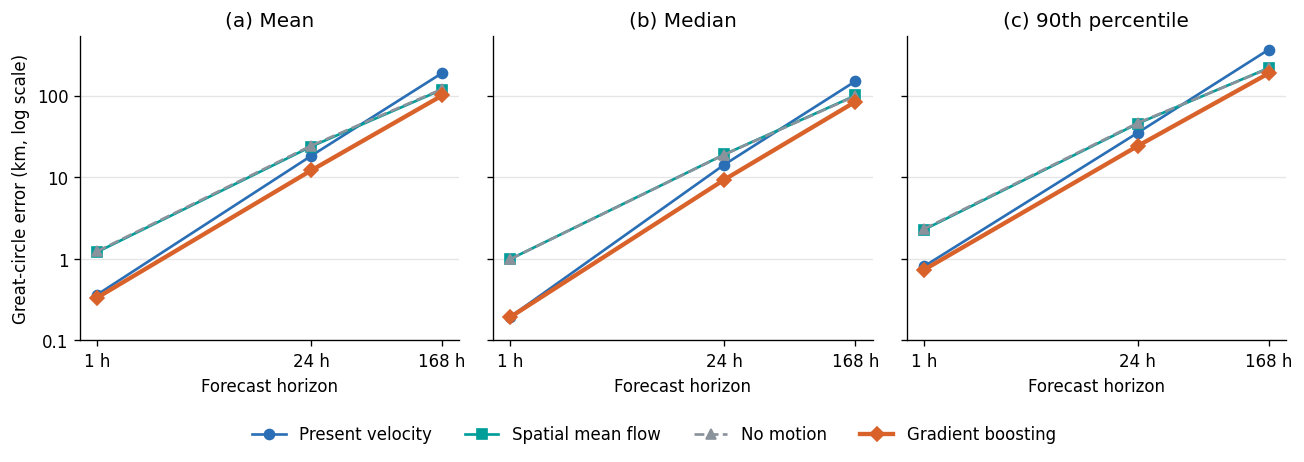

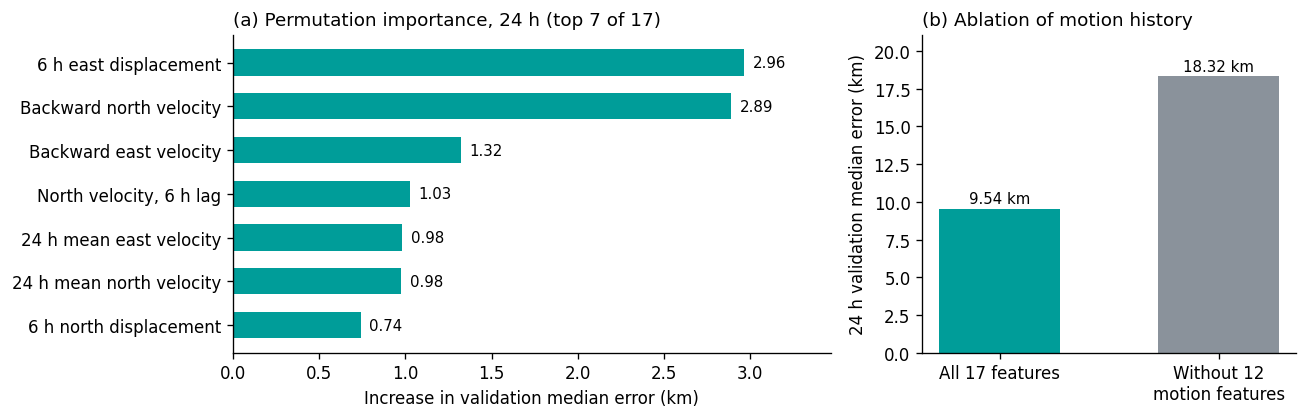

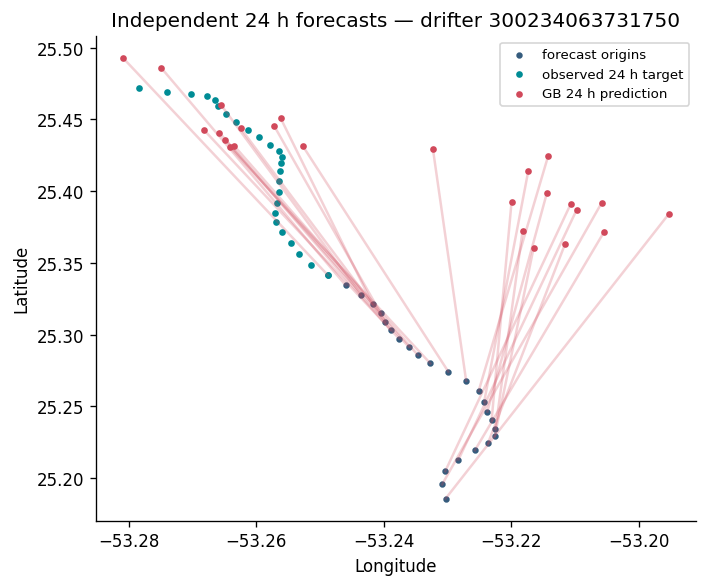

In [44]:
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
NAMES = {"Gradient Boosting": "Gradient boosting"}
ORDER = ["Present velocity", "Spatial mean flow", "No motion", "Gradient boosting"]
STYLE = {"Present velocity": dict(color="#2A6FB5", marker="o", lw=1.6),
         "Spatial mean flow": dict(color="#009D99", marker="s", lw=1.6),
         "No motion": dict(color="#8A929B", marker="^", ls="--", lw=1.6),
         "Gradient boosting": dict(color="#D9622B", marker="D", lw=2.6)}

# Figure 7: error against horizon
res = results.assign(method=results["method"].replace(NAMES))
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), sharey=True)
for ax, (col, title) in zip(axes, [("mean_km", "(a) Mean"), ("median_km", "(b) Median"), ("p90_km", "(c) 90th percentile")]):
    for m in ORDER:
        x = res[res["method"].eq(m)].sort_values("horizon_h")
        if len(x):
            ax.plot(x["horizon_h"], x[col], ms=6, label=m, **STYLE[m])
    ax.set(xscale="log", yscale="log", xticks=list(HORIZONS), xticklabels=[f"{h} h" for h in HORIZONS],
           title=title, xlabel="Forecast horizon")
    ax.minorticks_off()
    ax.grid(axis="y", color="#e5e5e5", lw=0.8)
axes[0].set_ylabel("Great-circle error (km, log scale)")
axes[0].set_yticks([0.1, 1, 10, 100])
axes[0].set_yticklabels(["0.1", "1", "10", "100"])
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.02))
fig.tight_layout(rect=(0, 0.08, 1, 1))
fig.savefig(FIG_DIR / "gb_error_vs_horizon.png", dpi=200)
plt.show()

# Figure 8: permutation importance and ablation
LABELS = {"recent_6h_east_km": "6 h east displacement", "recent_6h_north_km": "6 h north displacement",
          "u_bwd_ms": "Backward east velocity", "v_bwd_ms": "Backward north velocity",
          "u_bwd_mean_24h_ms": "24 h mean east velocity", "v_bwd_mean_24h_ms": "24 h mean north velocity",
          "u_bwd_lag_6_ms": "East velocity, 6 h lag", "v_bwd_lag_6_ms": "North velocity, 6 h lag",
          "u_bwd_lag_1_ms": "East velocity, 1 h lag", "v_bwd_lag_1_ms": "North velocity, 1 h lag",
          "u_bwd_std_24h_ms": "24 h east velocity spread", "v_bwd_std_24h_ms": "24 h north velocity spread"}
top = importance.head(7)
abl = ablation.set_index("feature_set")["median_km"]
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw=dict(width_ratios=[1.6, 1]))
y = np.arange(len(top))[::-1]
a.barh(y, top["median_error_increase_km"], color="#009D99", height=0.6)
a.set_yticks(y)
a.set_yticklabels([LABELS.get(f, f) for f in top["feature"]])
for yi, v in zip(y, top["median_error_increase_km"]):
    a.text(v + 0.05, yi, f"{v:.2f}", va="center", fontsize=9)
a.set_xlabel("Increase in validation median error (km)")
a.set_title("(a) Permutation importance, 24 h (top 7 of 17)", fontsize=11, loc="left")
a.set_xlim(0, max(top["median_error_increase_km"].max(), 0.1) * 1.17)
vals = [abl["all_features"], abl["without_motion_history"]]
b.bar([0, 1], vals, color=["#009D99", "#8A929B"], width=0.55)
b.set_xticks([0, 1])
b.set_xticklabels(["All 17 features", "Without 12\nmotion features"])
for x, v in zip([0, 1], vals):
    b.text(x, v + 0.02 * max(vals), f"{v:.2f} km", ha="center", fontsize=9)
b.set_ylabel("24 h validation median error (km)")
b.set_ylim(0, max(vals) * 1.15)
b.set_title("(b) Ablation of motion history", fontsize=11, loc="left")
fig.tight_layout()
fig.savefig(FIG_DIR / "gb_importance_ablation.png", dpi=200)
plt.show()

# Figure 9: independent 24 h forecasts from 25 consecutive origins of the drifter with most test origins
case_id = pred["buoy_id"].value_counts().index[0]
x = pred[pred["buoy_id"].eq(case_id)].sort_values("time").iloc[:25]
fig, ax = plt.subplots(figsize=(6, 5))
for _, r in x.iterrows():
    ax.plot([r["lon"], r["pred_lon_24"]], [r["lat"], r["pred_lat_24"]], color="#D1495B", alpha=0.25)
ax.scatter(x["lon"], x["lat"], s=8, c="#355C7D", label="forecast origins")
ax.scatter(x["lon_24"], x["lat_24"], s=9, c="#008C95", label="observed 24 h target")
ax.scatter(x["pred_lon_24"], x["pred_lat_24"], s=9, c="#D1495B", label="GB 24 h prediction")
ax.set(xlabel="Longitude", ylabel="Latitude", title=f"Independent 24 h forecasts — drifter {case_id}")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "gb_case_study_drifter.png", dpi=180)
plt.show()

### 15.12 Final results and complete report summary
Run the corrected notebook from the top. The final cell validates and exports explicit current-run tables; old report numbers are only a comparison.


In [45]:
summary = gb.set_index("horizon_h")[["mean_km", "median_km", "p90_km", "rmse_km"]].join(
    boot.set_index("horizon_h")[["ci95_low", "ci95_high"]])
print("Gradient boosting on the held-out test origins (km); 95% interval is for the median.")
display(summary.round(3))
print("\nFiles written:")
for p in sorted(OUT_DIR.glob("*")) + sorted(FIG_DIR.glob("*")):
    print("  ", p)

Gradient boosting on the held-out test origins (km); 95% interval is for the median.


,mean_km,median_km,p90_km,rmse_km,ci95_low,ci95_high
horizon_h,,,,,,
1,0.335,0.194,0.731,0.602,0.177,0.210
24,12.125,9.371,24.197,15.882,9.010,9.798
168,100.593,84.448,188.179,124.083,81.685,87.801



Files written:
   /content/member2_outputs/full_25edd24008c2/part3_outputs/cache_fit_cap192.pkl
   /content/member2_outputs/full_25edd24008c2/part3_outputs/cache_validation_cap192.pkl
   /content/member2_outputs/full_25edd24008c2/part3_outputs/gb_168h_east_north.joblib
   /content/member2_outputs/full_25edd24008c2/part3_outputs/gb_1h_east_north.joblib
   /content/member2_outputs/full_25edd24008c2/part3_outputs/gb_24h_east_north.joblib
   /content/member2_outputs/full_25edd24008c2/part3_outputs/gb_improvement_vs_baselines.csv
   /content/member2_outputs/full_25edd24008c2/part3_outputs/official_gb_conditional_errors.csv
   /content/member2_outputs/full_25edd24008c2/part3_outputs/official_gb_drifter_bootstrap_ci.csv
   /content/member2_outputs/full_25edd24008c2/part3_outputs/official_heldout_results.csv
   /content/member2_outputs/full_25edd24008c2/part3_outputs/official_test_gb_predictions.parquet
   /content/member2_outputs/full_25edd24008c2/part3_outputs/selected_model_configuration.j

In [46]:
# Complete report summary: explicit current-run sources only.
from datetime import datetime, timezone
from pathlib import Path
import hashlib
import json
import pandas as pd
import numpy as np
from IPython.display import display, Markdown

required = ["report_eda_tables", "report_eda_run_dir", "report_origin_alignment_verified",
            "baseline_results", "gb", "results", "boot", "conditional", "importance",
            "ablation", "trials", "coverage", "pred", "CHOSEN", "FEATURES", "manifest"]
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError("Run the corrected notebook from the top. Missing: " + ", ".join(missing))
assert report_eda_run_dir == str(Path(RUN_DIR).resolve()), "EDA and Part 3 run directories differ"
assert report_origin_alignment_verified, "Origin alignment has not been verified"

metrics = ["mean_km", "median_km", "p90_km", "rmse_km"]
assert set(gb.horizon_h) == set(HORIZONS) and len(gb) == len(HORIZONS)
assert not results.duplicated(["horizon_h", "method"]).any()
assert results["n"].eq(len(pred)).all()
assert np.isfinite(results[metrics].to_numpy()).all()
# Verify summary tables against the current predictions and baseline calculations.
for h in HORIZONS:
    row = gb.loc[gb.horizon_h.eq(h)].iloc[0]
    measured = summarise(pred[f"error_{h}_km"])
    np.testing.assert_allclose(row[metrics].to_numpy(dtype=float),
                               [measured[k] for k in metrics], rtol=1e-12, atol=1e-12)
expected_results = pd.concat([baseline_results, gb], ignore_index=True)
def canonical(frame):
    return frame.sort_values(["horizon_h", "method"]).reset_index(drop=True)
pd.testing.assert_frame_equal(canonical(results), canonical(expected_results), check_dtype=False)
assert set(boot.horizon_h) == set(HORIZONS) and not boot.horizon_h.duplicated().any()
assert boot.statistic.eq("median_km").all()
assert boot.ci95_low.le(boot.ci95_high).all()
np.testing.assert_allclose(boot.sort_values("horizon_h").median_km,
                           gb.sort_values("horizon_h").median_km)

report_tables = {title: df.copy(deep=True) for title, df in report_eda_tables.items()}
report_tables.update({
    "All models - held-out test errors (km)": canonical(results),
    "GB median error - drifter bootstrap 95% CI (km)": boot.copy(),
    "GB conditional test errors (km)": conditional.copy(),
    "Training and validation sampling": coverage.copy(),
    "Hyperparameter selection - validation only": trials.copy(),
    "Permutation importance - 24 h validation only": importance.copy(),
    "Feature ablation - 24 h validation only": ablation.copy(),
    "Model features": pd.DataFrame({"feature": FEATURES}),
})
improvement_rows = []
for h in HORIZONS:
    grow = gb.loc[gb.horizon_h.eq(h)].iloc[0]
    for _, brow in baseline_results.loc[baseline_results.horizon_h.eq(h)].iterrows():
        for metric in metrics:
            delta = float(brow[metric] - grow[metric])
            improvement_rows.append(dict(horizon_h=h, baseline=brow["method"], statistic=metric,
                gb_improvement_km=delta,
                gb_improvement_pct=100 * delta / brow[metric] if brow[metric] != 0 else np.nan))
report_tables["GB improvement over baselines - positive means lower error"] = pd.DataFrame(improvement_rows)

# Report reference values are comparisons only, never the source of reported results.
reference_rows = []
for h, values in REPORT_GB.items():
    actual = gb.loc[gb.horizon_h.eq(h)].iloc[0]
    for metric, reference in values.items():
        reference_rows.append(dict(horizon_h=h, statistic=metric, old_report=reference,
            current_run=float(actual[metric]), difference=float(actual[metric]-reference),
            match=bool(np.isclose(actual[metric], reference, rtol=1e-4))))
reference_check = pd.DataFrame(reference_rows)
report_tables["Old report reference check - use current_run in the report"] = reference_check

report_dir = Path(RUN_DIR) / "final_report_summary"
report_dir.mkdir(parents=True, exist_ok=True)
def as_markdown(frame):
    frame = frame.reset_index(drop=True)
    def fmt(value):
        if pd.isna(value): return "NA"
        if isinstance(value, (float, np.floating)): return f"{value:.6f}"
        return str(value).replace("|", "\\|").replace("\n", " ")
    lines = ["| " + " | ".join(map(str, frame.columns)) + " |",
             "| " + " | ".join(["---"] * len(frame.columns)) + " |"]
    lines.extend("| " + " | ".join(fmt(v) for v in row) + " |"
                 for row in frame.itertuples(index=False, name=None))
    return "\n".join(lines)

lines = ["# Gulf Stream — Complete Results for the Final Report", "",
    "Generated from explicit EDA, baseline and Part 3 tables in the current kernel.", "",
    "## Evaluation and interpretation", "",
    f"- Test origins: {len(pred):,}; contributing drifters: {pred.buoy_id.nunique():,}.",
    f"- Assigned training/test drifters: {len(train_ids):,}/{len(test_ids):,}.",
    "- Test split: by drifter, seed 42; 24 h history and 168 h future in one continuous segment.",
    f"- Model/validation seed: {SEED}; up to {MAX_ORIGINS_PER_DRIFTER} origins per fitting/validation drifter.",
    "- Errors: great-circle endpoint distance in km. All methods use aligned test origins.",
    f"- GB intervals: 95% percentile intervals for the median, {BOOTSTRAP_REPS} drifter bootstrap replicates.",
    "- Importance, ablation and parameter selection use validation data, not test data.",
    "- CI overlap does not establish significance of paired model differences.",
    "- GB target coordinates are exported as float32; baselines retain their original precision.",
    "- CSV tables preserve numeric precision; Markdown displays six decimals.", "",
    "## Current results", ""]
for h in HORIZONS:
    row = gb.loc[gb.horizon_h.eq(h)].iloc[0]
    best = results.loc[results.horizon_h.eq(h)].sort_values("median_km").iloc[0]
    lines.append(f"- {h} h: GB median {row.median_km:.6f} km; lowest median: {best['method']} ({best.median_km:.6f} km).")
if not reference_check["match"].all():
    lines += ["", "**Old report numbers differ from this run. Update the abstract, text, tables and figure captions using current-run results below.**"]
lines += ["", "## Complete numerical tables", ""]
index_rows = []
for number, (title, frame) in enumerate(report_tables.items(), 1):
    filename = f"table_{number:02d}.csv"
    path = report_dir / filename
    frame.to_csv(path, index=False)
    index_rows.append(dict(title=title, file=filename, rows=len(frame),
                          sha256=hashlib.sha256(path.read_bytes()).hexdigest()))
    lines += [f"### {number}. {title}", "", as_markdown(frame), ""]
pd.DataFrame(index_rows).to_csv(report_dir / "table_index.csv", index=False)
provenance = dict(generated_utc=datetime.now(timezone.utc).isoformat(), run_dir=str(Path(RUN_DIR).resolve()),
    data_manifest=manifest, model_settings=CHOSEN, model_seed=SEED,
    rebuild_feature_cache=REBUILD_CACHE, origin_identity_and_targets_checked=True,
    old_report_matches=bool(reference_check["match"].all()), tables=index_rows,
    package_versions={"numpy": np.__version__, "pandas": pd.__version__, "sklearn": sklearn.__version__})
(report_dir / "provenance.json").write_text(json.dumps(provenance, indent=2, default=str), encoding="utf-8")
report_path = report_dir / "DATA3001_COMPLETE_RESULTS_SUMMARY.md"
report_path.write_text("\n".join(lines), encoding="utf-8")
display(Markdown(f"Complete report summary saved: `{report_path}`"))
print(f"Verified and exported {len(report_tables)} tables. CSV index: {report_dir / 'table_index.csv'}")


Complete report summary saved: `/content/member2_outputs/full_25edd24008c2/final_report_summary/DATA3001_COMPLETE_RESULTS_SUMMARY.md`

Verified and exported 29 tables. CSV index: /content/member2_outputs/full_25edd24008c2/final_report_summary/table_index.csv
